# **04 – Data Analysis**

## **0. Giới thiệu**

Notebook này triển khai phân tích định lượng và mô hình hóa Học máy cho toàn bộ **6 câu hỏi nghiên cứu** đã xây dựng tại *Notebook 03 – Question Formulation*, dựa trên bộ dữ liệu đã làm sạch tất định **`step4_clean_v1`** ([chuyenhocielts/myanimelist-clean](https://www.kaggle.com/datasets/chuyenhocielts/myanimelist-clean)).

Mỗi câu hỏi tuân thủ chặt chẽ cấu trúc chuẩn của đề bài:
1. **Tiền xử lý dữ liệu (*Preprocessing*):** Giải thích quy trình bằng văn bản trước khi viết code; kiểm tra và báo cáo số dòng trước/sau bằng `report_row_change` / `verify_merge` cho mọi thao tác lọc, gộp hoặc loại bỏ dòng.
2. **Phân tích dữ liệu & Mô hình hóa (*Analysis*):** Nêu rõ lý do chọn phương pháp thống kê (kiểm soát biến nhiễu, khoảng tin cậy Bootstrap, kiểm định phi tham số, kiểm tra độ bền vững `D1–D6`) hoặc thiết kế `scikit-learn Pipeline` chống rò rỉ dữ liệu (`GroupKFold` / `TimeSeriesSplit`).
3. **Kết quả, Trực quan hóa & Nhận định (*Results & Interpretation*):** Tối thiểu **2 biểu đồ đa thành phần có đầy đủ tiêu đề, nhãn trục, đơn vị và chú giải** cho mỗi câu hỏi, kèm câu trả lời định lượng trực tiếp, phát hiện bất ngờ và giới hạn phạm vi.

## **0.1. Import thư viện, Load dữ liệu sạch và Khởi tạo bảng tổng hợp nền**

In [1]:
from pathlib import Path
import sys
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
    HistGradientBoostingRegressor,
    RandomForestRegressor,
)
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_recall_curve,
    precision_score,
    r2_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    GroupKFold,
    GroupShuffleSplit,
    TimeSeriesSplit,
)
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "environment.yml").exists()), Path.cwd())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.audit import report_row_change, verify_merge
from src.models import build_tabular_preprocessor, compute_permutation_importance_df
from src.utils import (
    bootstrap_ci,
    extract_franchise_relations,
    iter_list_parts,
    load_clean_tables,
    setup_plot_style,
)

setup_plot_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)

anime, users, list_parts, clean_logs = load_clean_tables(ROOT)
roles_df, edges_df = extract_franchise_relations(anime)
print(f"Loaded: anime={len(anime):,}, users={len(users):,}, parquet_parts={len(list_parts)}, sequel_edges={len(edges_df):,}")

Loaded: anime=14,478, users=302,673, parquet_parts=27, sequel_edges=2,533


### **0.2. Trích xuất thống kê hành vi từ 80,075,053 dòng Parquet (Duyệt tối ưu bộ nhớ)**
Để phục vụ đồng bộ cho cả 6 câu hỏi mà không nạp toàn bộ 80 triệu dòng vào RAM cùng lúc, ta thực hiện:
- **Lượt 1 (Toàn cục 80,075,053 dòng, chỉ chiếu các cột số/thời gian):** Tổng hợp chính xác số người xem theo từng trạng thái, tiến độ bỏ dở (`drop_progress_ratio`), thống kê chu kỳ Quý (`2006Q1–2018Q2`) và ma trận độ trễ xem (`watch_lag_years`).
- **Lượt 2 (Mẫu ngẫu nhiên phân tầng 20,000 người dùng tích cực, `seed=42`):** Thu thập trọn vẹn danh sách cá nhân của 20,000 tài khoản (~5.68 triệu dòng) để theo dõi hành vi nối tiếp Phần 1 -> Phần 2 trên **cùng một tài khoản** (Q3), tính độ hào phóng cá nhân `user_score_leniency` (Q4) và xây dựng tập huấn luyện `Leave-One-Out` theo nhóm người dùng (Q5).

In [2]:
anime_ep_map = anime.set_index("anime_id")["episodes_clean"]
anime_score_map = anime.set_index("anime_id")["score_clean"]
anime_year_map = anime.set_index("anime_id")["aired_start_year_clean"]
anime_type_map = anime.set_index("anime_id")["type_clean"]

anime_status_counts = {s: Counter() for s in [1, 2, 3, 4, 6]}
anime_rated_n = Counter()
anime_score_sum = Counter()
anime_drop_ep_sum = Counter()
anime_drop_ep_n = Counter()
anime_drop_early25_n = Counter()

ym_score_sum = Counter()
ym_score_n = Counter()
ym_completed = Counter()
ym_dropped = Counter()
fin_year_lag_stats: dict[tuple[int, str, str], list[float]] = {}
cohort_era_fin: dict[tuple[str, str], list[float]] = {}

total_rows_pass1 = 0
valid_fdate_rows = 0
valid_lag_tv_rows = 0

cols_pass1 = [
    "anime_id", "my_status_clean", "my_score_clean",
    "my_watched_episodes_clean", "my_finish_date_clean", "my_finish_year_clean",
]

for _, df_p in iter_list_parts(list_parts, columns=cols_pass1):
    total_rows_pass1 += len(df_p)
    for s in [1, 2, 3, 4, 6]:
        anime_status_counts[s].update(df_p.loc[df_p["my_status_clean"].eq(s), "anime_id"].value_counts().to_dict())

    rated_p = df_p.dropna(subset=["my_score_clean"])
    anime_rated_n.update(rated_p["anime_id"].value_counts().to_dict())
    anime_score_sum.update(rated_p.groupby("anime_id")["my_score_clean"].sum().astype(float).to_dict())

    # Tiến độ tập đã xem khi bỏ dở (Q1)
    dropped_p = df_p[df_p["my_status_clean"].eq(4) & df_p["my_watched_episodes_clean"].notna()]
    if len(dropped_p):
        ep_t = dropped_p["anime_id"].map(anime_ep_map)
        ok_d = dropped_p[ep_t.notna() & (ep_t > 0)].copy()
        if len(ok_d):
            prog = ok_d["my_watched_episodes_clean"].astype(float) / ep_t.loc[ok_d.index].astype(float)
            ok_d["prog"] = prog
            ok_d["early25"] = (prog <= 0.25).astype(int)
            anime_drop_ep_sum.update(ok_d.groupby("anime_id")["prog"].sum().to_dict())
            anime_drop_ep_n.update(ok_d.groupby("anime_id")["prog"].size().to_dict())
            anime_drop_early25_n.update(ok_d.groupby("anime_id")["early25"].sum().to_dict())

    # Chuỗi thời gian theo Quý hoàn thành (Q2)
    fdate_p = df_p.dropna(subset=["my_finish_date_clean"])
    valid_fdate_rows += len(fdate_p)
    if len(fdate_p):
        qp = pd.to_datetime(fdate_p["my_finish_date_clean"]).dt.to_period("Q").astype(str)
        st_sub = fdate_p["my_status_clean"]
        ym_completed.update(qp[st_sub.eq(2)].value_counts().to_dict())
        ym_dropped.update(qp[st_sub.eq(4)].value_counts().to_dict())
        rf = fdate_p.dropna(subset=["my_score_clean"])
        if len(rf):
            qp_r = pd.to_datetime(rf["my_finish_date_clean"]).dt.to_period("Q").astype(str)
            ym_score_n.update(qp_r.value_counts().to_dict())
            ym_score_sum.update(rf["my_score_clean"].astype(float).groupby(qp_r).sum().to_dict())

    # Độ trễ xem (watch_lag_years) và Cohort phát sóng x hoàn thành (Q2)
    fy_p = df_p.dropna(subset=["my_finish_year_clean", "my_score_clean"])
    if len(fy_p):
        fy = fy_p["my_finish_year_clean"].astype(int)
        ay = fy_p["anime_id"].map(anime_year_map)
        tp = fy_p["anime_id"].map(anime_type_map)
        ok_m = fy.between(2006, 2018) & ay.notna() & (fy >= ay)
        if ok_m.any():
            fy_ok = fy[ok_m]
            ay_ok = ay[ok_m].astype(int)
            tp_ok = tp[ok_m]
            sc_ok = fy_p.loc[ok_m, "my_score_clean"].astype(float).to_numpy()
            lag = fy_ok - ay_ok
            lag_bin = np.select(
                [lag == 0, lag.between(1, 2), lag.between(3, 5), lag > 5],
                ["0 năm (Xem ngay)", "1–2 năm", "3–5 năm", ">5 năm (Kinh điển)"],
                default="Khác",
            )
            tp_grp = np.where(tp_ok.eq("TV"), "TV", "Non-TV")
            valid_lag_tv_rows += int((tp_grp == "TV").sum())
            tmp = pd.DataFrame({"fy": fy_ok.to_numpy(), "lb": lag_bin, "tp": tp_grp, "sc": sc_ok})
            for (yv, lbv, tpv), rg in tmp.groupby(["fy", "lb", "tp"])["sc"].agg(["count", "sum"]).iterrows():
                key = (int(yv), str(lbv), str(tpv))
                if key not in fin_year_lag_stats:
                    fin_year_lag_stats[key] = [0.0, 0.0]
                fin_year_lag_stats[key][0] += float(rg["count"])
                fin_year_lag_stats[key][1] += float(rg["sum"])

            # Cohort matrix trên dòng TV
            tv_mask = tp_ok.eq("TV").to_numpy()
            if tv_mask.any():
                ay_tv = ay_ok.to_numpy()[tv_mask]
                fy_tv = fy_ok.to_numpy()[tv_mask]
                sc_tv = sc_ok[tv_mask]
                a_era = np.select(
                    [ay_tv < 2000, (ay_tv >= 2000) & (ay_tv <= 2005), (ay_tv >= 2006) & (ay_tv <= 2010),
                     (ay_tv >= 2011) & (ay_tv <= 2014), ay_tv >= 2015],
                    ["Trước 2000", "2000–2005", "2006–2010", "2011–2014", "2015–2018"],
                    default="Khác",
                )
                f_era = np.select(
                    [fy_tv <= 2009, (fy_tv >= 2010) & (fy_tv <= 2012), (fy_tv >= 2013) & (fy_tv <= 2015), fy_tv >= 2016],
                    ["Xem 2006–2009", "Xem 2010–2012", "Xem 2013–2015", "Xem 2016–2018"],
                    default="Khác",
                )
                ctmp = pd.DataFrame({"ae": a_era, "fe": f_era, "sc": sc_tv})
                for (aev, fev), rg in ctmp.groupby(["ae", "fe"])["sc"].agg(["count", "sum"]).iterrows():
                    ck = (str(aev), str(fev))
                    if ck not in cohort_era_fin:
                        cohort_era_fin[ck] = [0.0, 0.0]
                    cohort_era_fin[ck][0] += float(rg["count"])
                    cohort_era_fin[ck][1] += float(rg["sum"])

# Lượt 2: Trích xuất toàn bộ lịch sử của 20,000 người dùng tích cực chọn ngẫu nhiên
rng_master = np.random.default_rng(42)
active_pool = users.loc[users["has_list_rows"], "username"].to_numpy()
sampled_20k_users = set(rng_master.choice(active_pool, size=20_000, replace=False).tolist())

sampled_parts = []
for _, df_p in iter_list_parts(list_parts, columns=["username", "anime_id", "my_status_clean", "my_score_clean"]):
    sub_u = df_p[df_p["username"].isin(sampled_20k_users)]
    if len(sub_u):
        sampled_parts.append(sub_u)
sampled_list_df = pd.concat(sampled_parts, ignore_index=True)

# Xây dựng bảng anime_full kết hợp metadata + hành vi thực tế + vai trò nhượng quyền
anime_agg = pd.DataFrame({
    "s1_watching": pd.Series(anime_status_counts[1], dtype=float),
    "s2_completed": pd.Series(anime_status_counts[2], dtype=float),
    "s3_onhold": pd.Series(anime_status_counts[3], dtype=float),
    "s4_dropped": pd.Series(anime_status_counts[4], dtype=float),
    "s6_plantowatch": pd.Series(anime_status_counts[6], dtype=float),
    "rated_n": pd.Series(anime_rated_n, dtype=float),
    "score_sum": pd.Series(anime_score_sum, dtype=float),
    "drop_prog_sum": pd.Series(anime_drop_ep_sum, dtype=float),
    "drop_prog_n": pd.Series(anime_drop_ep_n, dtype=float),
    "drop_early25_n": pd.Series(anime_drop_early25_n, dtype=float),
}).fillna(0)

anime_agg["on_list_total"] = anime_agg[["s1_watching", "s2_completed", "s3_onhold", "s4_dropped", "s6_plantowatch"]].sum(axis=1)
anime_agg["active_starters"] = anime_agg[["s1_watching", "s2_completed", "s3_onhold", "s4_dropped"]].sum(axis=1)
anime_agg["active_drop_rate"] = np.where(anime_agg["active_starters"] > 0, anime_agg["s4_dropped"] / anime_agg["active_starters"], np.nan)
anime_agg["abandon_rate"] = np.where(anime_agg["active_starters"] > 0, (anime_agg["s4_dropped"] + anime_agg["s3_onhold"]) / anime_agg["active_starters"], np.nan)
anime_agg["completion_rate"] = np.where(anime_agg["active_starters"] > 0, anime_agg["s2_completed"] / anime_agg["active_starters"], np.nan)
anime_agg["mean_drop_progress"] = np.where(anime_agg["drop_prog_n"] >= 20, anime_agg["drop_prog_sum"] / anime_agg["drop_prog_n"], np.nan)
anime_agg["early25_drop_share"] = np.where(anime_agg["drop_prog_n"] >= 20, anime_agg["drop_early25_n"] / anime_agg["drop_prog_n"], np.nan)

anime_full = anime.merge(anime_agg, left_on="anime_id", right_index=True, how="left").merge(roles_df, on="anime_id", how="left")
verify_merge(
    "Khởi tạo bảng nền anime_full",
    anime,
    anime_agg.reset_index().rename(columns={"index": "anime_id"}),
    anime_full,
    on="anime_id",
    how="left",
    reason="Gắn thống kê hành vi từ 80,075,053 dòng và vai trò nhượng quyền vào 14,478 tựa anime",
)
print(f"Tổng dòng Parquet đã quét: {total_rows_pass1:,} | Số dòng mẫu 20,000 user: {len(sampled_list_df):,}")

[MERGE D1] Khởi tạo bảng nền anime_full (left on ['anime_id']): left=14,478, right=14,478 -> merged=14,478 (+0) | unmatched left keys=0, unmatched right keys=0 | Lý do: Gắn thống kê hành vi từ 80,075,053 dòng và vai trò nhượng quyền vào 14,478 tựa anime
Tổng dòng Parquet đã quét: 80,075,053 | Số dòng mẫu 20,000 user: 5,683,544


---
## **1. Phân tích Câu hỏi 1 (Non-ML — Phụ trách: Trần Trọng Tú)**

> ***"Trong nhóm người dùng đã thực sự bắt đầu xem một bộ anime (`my_status_clean` $\in \{1, 2, 3, 4\}$), tổng thời lượng cam kết (`total_runtime_hours` và quy mô số tập) ảnh hưởng như thế nào đến tỷ lệ bỏ dở thực tế (`active_drop_rate`) cũng như tiến độ bỏ cuộc sớm (`early25_drop_share`), và xu hướng này có còn giữ nguyên sau khi kiểm soát định dạng phát hành (`type_clean`) cùng thể loại chính hay không?"***

### **1.1. Tiền xử lý dữ liệu**
#### **1.1.1. Giải thích bằng văn bản**
1. **Chỉ giữ các bộ anime đã hoàn tất phát sóng (`status_clean == 'Finished Airing'`):** Các bộ đang chiếu (`Currently Airing`) hoặc chưa chiếu (`Not yet aired`) chưa có kết cục hoàn thành/bỏ dở ổn định.
2. **Yêu cầu đầy đủ `episodes_clean`, `duration_minutes_clean` và `type_clean`:** Cần thiết để tính chính xác tổng thời lượng cam kết `total_runtime_hours = episodes_clean * duration_minutes_clean / 60`.
3. **Loại bỏ nhiễu mẫu nhỏ (`active_starters >= 100`):** Một anime chỉ có vài chục người xem dễ dao động tỷ lệ bỏ dở cực đoan; ngưỡng 100 người bắt đầu xem đảm bảo ước lượng tỷ lệ ổn định (đồng thời sẽ được kiểm tra độ bền vững **D6** ở ngưỡng `500` và `1,000`).

In [3]:
# 1.1.2. Triển khai tiền xử lý Câu hỏi 1 kèm kiểm toán số dòng
q1_step0 = anime_full.copy()
q1_step1 = q1_step0[q1_step0["status_clean"].eq("Finished Airing")].copy()
report_row_change("Q1.B1 Lọc Finished Airing", q1_step0, q1_step1, "Chỉ xét anime đã phát sóng xong để kết cục xem ổn định")

q1_step2 = q1_step1[
    q1_step1["episodes_clean"].notna()
    & q1_step1["duration_minutes_clean"].notna()
    & q1_step1["type_clean"].notna()
].copy()
report_row_change("Q1.B2 Đủ số tập, thời lượng và định dạng", q1_step1, q1_step2, "Loại các dòng thiếu thông tin tính tổng thời lượng")

q1_df = q1_step2[q1_step2["active_starters"] >= 100].copy()
report_row_change("Q1.B3 Quy mô tối thiểu active_starters >= 100", q1_step2, q1_df, "Khử nhiễu phương sai cao ở các anime quá ít người xem")

# Tạo biến dẫn xuất (D3)
q1_df["total_runtime_hours"] = q1_df["episodes_clean"].astype(float) * q1_df["duration_minutes_clean"].astype(float) / 60.0
q1_df["ep_bucket"] = pd.cut(
    q1_df["episodes_clean"].astype(float),
    bins=[0, 1, 6, 13, 26, 52, 10000],
    labels=["1 tập", "2–6 tập", "7–13 tập\n(1 cour)", "14–26 tập\n(2 cour)", "27–52 tập", "53+ tập"],
)

q1_tv = q1_df[q1_df["type_clean"].eq("TV")].copy()
report_row_change("Q1.B4 Tách riêng nhóm TV để kiểm soát định dạng (D4)", q1_df, q1_tv, "So sánh công bằng giữa các mùa anime truyền hình")

[AUDIT] Q1.B1 Lọc Finished Airing: 14,478 -> 13,791 dòng (-687 | -4.75%) | Lý do: Chỉ xét anime đã phát sóng xong để kết cục xem ổn định
[AUDIT] Q1.B2 Đủ số tập, thời lượng và định dạng: 13,791 -> 13,657 dòng (-134 | -0.97%) | Lý do: Loại các dòng thiếu thông tin tính tổng thời lượng


[AUDIT] Q1.B3 Quy mô tối thiểu active_starters >= 100: 13,657 -> 9,427 dòng (-4,230 | -30.97%) | Lý do: Khử nhiễu phương sai cao ở các anime quá ít người xem
[AUDIT] Q1.B4 Tách riêng nhóm TV để kiểm soát định dạng (D4): 9,427 -> 3,086 dòng (-6,341 | -67.26%) | Lý do: So sánh công bằng giữa các mùa anime truyền hình


{'step': 'Q1.B4 Tách riêng nhóm TV để kiểm soát định dạng (D4)',
 'before_rows': 9427,
 'after_rows': 3086,
 'delta_rows': -6341,
 'delta_pct': -67.2642,
 'reason': 'So sánh công bằng giữa các mùa anime truyền hình'}

### **1.2. Phân tích dữ liệu**
#### **1.2.1. Giải thích phương pháp phân tích (Tích hợp D1, D3, D4, D5, D6)**
- **Định lượng độ bất định (D5):** Với mỗi bậc độ dài tập, tính tỷ lệ bỏ dở trung bình kèm **khoảng tin cậy Bootstrap 95%** (1,000 lần lấy mẫu lại), kiểm định tương quan hạng **Spearman** giữa `total_runtime_hours` và `active_drop_rate`, và kiểm định phi tham số **Mann–Whitney U** giữa cấu trúc chuẩn *1-cour* (10–13 tập) và *2-cour* (22–26 tập).
- **Kiểm soát biến nhiễu (D4):** So sánh *1-cour*, *2-cour* và *Long-running (27+ tập)* bên trong từng thể loại lớn (`Action`, `Comedy`, `Drama`, `Fantasy`, `Romance`, `Sci-Fi`) trên tập chỉ gồm `TV` để loại trừ khả năng chênh lệch do Movie/OVA ngắn tập hoặc do thể loại.
- **Kiểm tra độ bền vững (D6):** Thử nghiệm lại kết luận khi nâng ngưỡng mẫu từ `100` lên `500` và `1,000` người xem, đồng thời thay biến mục tiêu từ `active_drop_rate` sang `abandon_rate = (dropped + on_hold) / active_starters`.

In [4]:
# 1.2.2. Triển khai thống kê, kiểm soát biến nhiễu và kiểm tra độ bền vững (Q1)
q1_summary_rows = []
for bucket_label, grp in q1_df.groupby("ep_bucket", observed=True):
    mean_dr, lo_dr, hi_dr = bootstrap_ci(grp["active_drop_rate"] * 100, np.mean, n_boot=1000)
    early_pct = float(grp["early25_drop_share"].mean() * 100)
    med_prog = float(grp["mean_drop_progress"].median() * 100)
    q1_summary_rows.append({
        "Nhóm số tập": str(bucket_label).replace("\n", " "),
        "Số anime": len(grp),
        "Drop Rate TB (%)": round(mean_dr, 2),
        "95% CI Low (%)": round(lo_dr, 2),
        "95% CI High (%)": round(hi_dr, 2),
        "Trung vị tiến độ lúc bỏ (%)": round(med_prog, 2),
        "Tỷ lệ bỏ trong 25% đầu (%)": round(early_pct, 2),
    })
q1_summary_tbl = pd.DataFrame(q1_summary_rows)
display(q1_summary_tbl)

# Phân tích kiểm soát biến nhiễu trên TV: 1-Cour vs 2-Cour vs Long-running theo từng thể loại
q1_tv["cour_structure"] = np.select(
    [q1_tv["episodes_clean"].between(10, 13), q1_tv["episodes_clean"].between(22, 26), q1_tv["episodes_clean"] >= 27],
    ["1-Cour (10–13 tập)", "2-Cour (22–26 tập)", "Dài tập (27+ tập)"],
    default="Khác",
)
c1_vals = q1_tv.loc[q1_tv["cour_structure"].eq("1-Cour (10–13 tập)"), "active_drop_rate"] * 100
c2_vals = q1_tv.loc[q1_tv["cour_structure"].eq("2-Cour (22–26 tập)"), "active_drop_rate"] * 100
mw_stat, mw_pval = stats.mannwhitneyu(c1_vals, c2_vals, alternative="two-sided")
rho_rt, p_rt = stats.spearmanr(q1_tv["total_runtime_hours"], q1_tv["active_drop_rate"])
print(f"TV 1-Cour ({c1_vals.mean():.2f}%) vs 2-Cour ({c2_vals.mean():.2f}%): Mann-Whitney U p-value = {mw_pval:.4e}")
print(f"Spearman (total_runtime_hours vs active_drop_rate trên TV, n={len(q1_tv):,}): r_s = {rho_rt:.4f} (p = {p_rt:.4e})")

genre_cour_rows = []
for g_name in ["Action", "Comedy", "Drama", "Fantasy", "Romance", "Sci-Fi"]:
    g_sub = q1_tv[
        q1_tv["genre_clean"].fillna("").str.contains(rf"\b{g_name}\b", regex=True)
        & q1_tv["cour_structure"].isin(["1-Cour (10–13 tập)", "2-Cour (22–26 tập)", "Dài tập (27+ tập)"])
    ]
    for c_label, c_grp in g_sub.groupby("cour_structure"):
        genre_cour_rows.append({
            "Thể loại": g_name,
            "Cấu trúc mùa": c_label,
            "Drop Rate TB (%)": c_grp["active_drop_rate"].mean() * 100,
            "n": len(c_grp),
        })
genre_cour_df = pd.DataFrame(genre_cour_rows)

# Kiểm tra độ bền vững D6 qua các ngưỡng lọc mẫu & định nghĩa ngừng xem
robust_rows = []
for thr in [100, 500, 1000]:
    sub_r = q1_step2[q1_step2["type_clean"].eq("TV") & (q1_step2["active_starters"] >= thr)]
    for label_c, mask_c in [
        ("1-Cour (10–13)", sub_r["episodes_clean"].between(10, 13)),
        ("2-Cour (22–26)", sub_r["episodes_clean"].between(22, 26)),
        ("Dài tập (27+)", sub_r["episodes_clean"] >= 27),
    ]:
        robust_rows.append({
            "Ngưỡng mẫu": f"active_starters >= {thr}",
            "Nhóm mùa": label_c,
            "Active Drop Rate (%)": round(float(sub_r.loc[mask_c, "active_drop_rate"].mean() * 100), 2),
            "Abandon Rate (Drop + On-Hold, %)": round(float(sub_r.loc[mask_c, "abandon_rate"].mean() * 100), 2),
        })
robust_q1_df = pd.DataFrame(robust_rows)
print("\n--- Bảng kiểm tra độ bền vững (D6) ---")
display(robust_q1_df)

,Nhóm số tập,Số anime,Drop Rate TB (%),95% CI Low (%),95% CI High (%),Trung vị tiến độ lúc bỏ (%),Tỷ lệ bỏ trong 25% đầu (%)
0,1 tập,3945,2.21,2.15,2.29,14.29,84.13
1,2–6 tập,2038,4.07,3.96,4.19,24.00,61.95
2,7–13 tập (1 cour),1784,9.13,8.81,9.44,21.10,71.40
3,14–26 tập (2 cour),849,10.39,9.92,10.87,18.07,74.92
4,27–52 tập,590,12.35,11.77,12.94,13.58,80.72
5,53+ tập,221,14.63,13.61,15.67,12.56,80.48


TV 1-Cour (9.87%) vs 2-Cour (10.79%): Mann-Whitney U p-value = 5.5444e-04
Spearman (total_runtime_hours vs active_drop_rate trên TV, n=3,086): r_s = 0.1317 (p = 2.0301e-13)



--- Bảng kiểm tra độ bền vững (D6) ---


,Ngưỡng mẫu,Nhóm mùa,Active Drop Rate (%),"Abandon Rate (Drop + On-Hold, %)"
0,active_starters >= 100,1-Cour (10–13),9.87,15.97
1,active_starters >= 100,2-Cour (22–26),10.79,19.91
2,active_starters >= 100,Dài tập (27+),13.06,24.71
3,active_starters >= 500,1-Cour (10–13),9.54,15.44
4,active_starters >= 500,2-Cour (22–26),9.90,18.78
5,active_starters >= 500,Dài tập (27+),11.69,22.68
6,active_starters >= 1000,1-Cour (10–13),9.44,15.27
7,active_starters >= 1000,2-Cour (22–26),9.68,18.49
8,active_starters >= 1000,Dài tập (27+),11.10,21.84


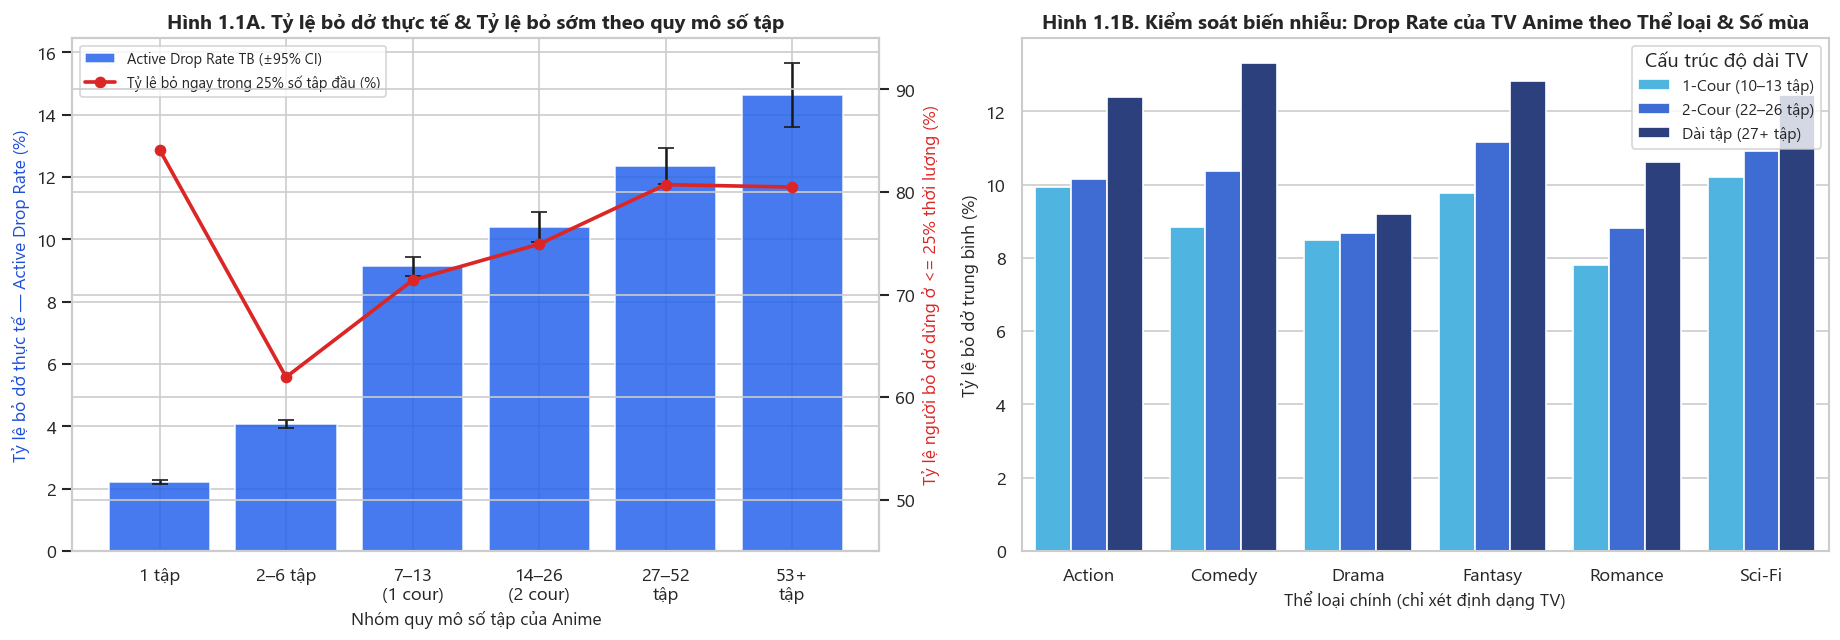

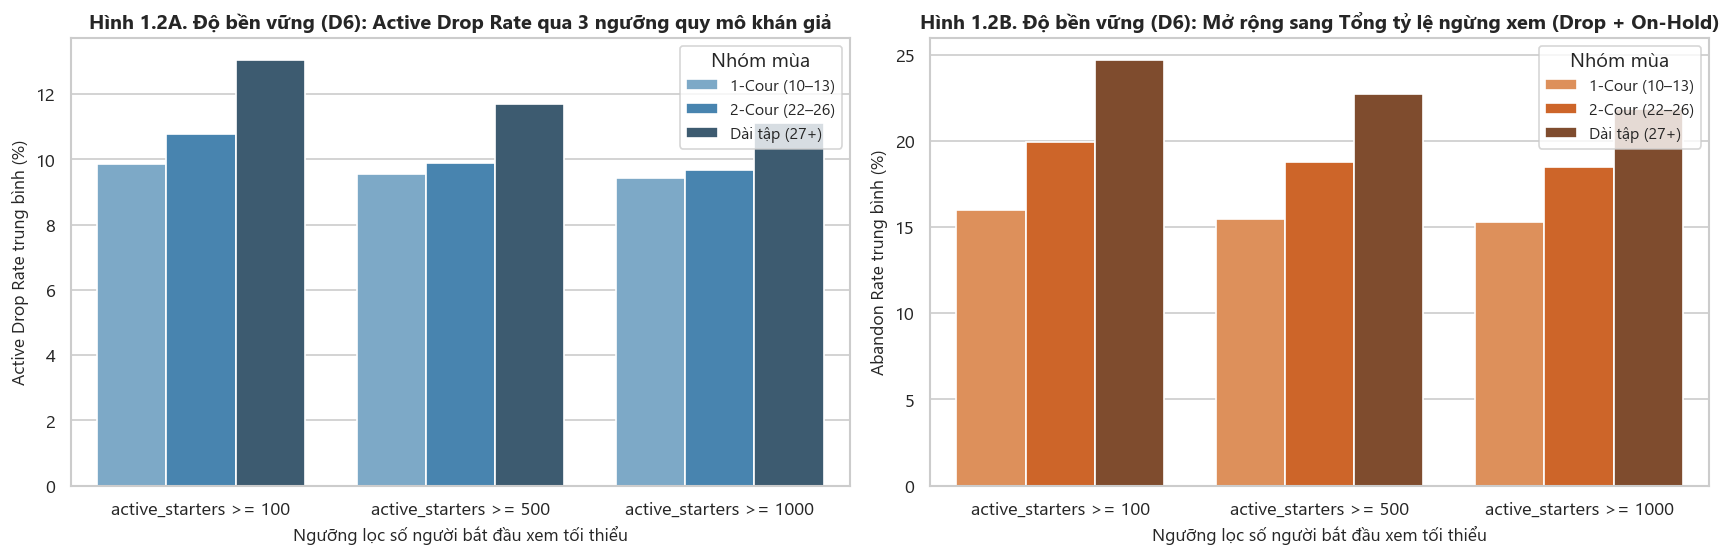

In [5]:
# Trực quan hóa Câu hỏi 1 (Hình 1.1 và Hình 1.2)
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.5))

# Hình 1.1A: Drop rate + 95% CI & Early-25% drop share
x_pos = np.arange(len(q1_summary_tbl))
means = q1_summary_tbl["Drop Rate TB (%)"].to_numpy()
yerr_low = means - q1_summary_tbl["95% CI Low (%)"].to_numpy()
yerr_high = q1_summary_tbl["95% CI High (%)"].to_numpy() - means

bars = axes[0].bar(x_pos, means, yerr=[yerr_low, yerr_high], capsize=5, color="#2563eb", alpha=0.85, label="Active Drop Rate TB (±95% CI)")
ax0_twin = axes[0].twinx()
ax0_twin.plot(x_pos, q1_summary_tbl["Tỷ lệ bỏ trong 25% đầu (%)"], color="#dc2626", marker="o", lw=2.2, label="Tỷ lệ bỏ ngay trong 25% số tập đầu (%)")
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(["1 tập", "2–6 tập", "7–13\n(1 cour)", "14–26\n(2 cour)", "27–52\ntập", "53+\ntập"])
axes[0].set_title("Hình 1.1A. Tỷ lệ bỏ dở thực tế & Tỷ lệ bỏ sớm theo quy mô số tập")
axes[0].set_xlabel("Nhóm quy mô số tập của Anime")
axes[0].set_ylabel("Tỷ lệ bỏ dở thực tế — Active Drop Rate (%)", color="#1d4ed8")
ax0_twin.set_ylabel("Tỷ lệ người bỏ dở dừng ở <= 25% thời lượng (%)", color="#dc2626")
ax0_twin.set_ylim(45, 95)
lines1, labels1 = axes[0].get_legend_handles_labels()
lines2, labels2 = ax0_twin.get_legend_handles_labels()
axes[0].legend(lines1 + lines2, labels1 + labels2, loc="upper left", fontsize=8.8)

# Hình 1.1B: Kiểm soát biến nhiễu theo thể loại trên định dạng TV
sns.barplot(
    data=genre_cour_df,
    x="Thể loại",
    y="Drop Rate TB (%)",
    hue="Cấu trúc mùa",
    hue_order=["1-Cour (10–13 tập)", "2-Cour (22–26 tập)", "Dài tập (27+ tập)"],
    palette=["#38bdf8", "#2563eb", "#1e3a8a"],
    ax=axes[1],
)
axes[1].set_title("Hình 1.1B. Kiểm soát biến nhiễu: Drop Rate của TV Anime theo Thể loại & Số mùa")
axes[1].set_xlabel("Thể loại chính (chỉ xét định dạng TV)")
axes[1].set_ylabel("Tỷ lệ bỏ dở trung bình (%)")
axes[1].legend(title="Cấu trúc độ dài TV")
plt.tight_layout()
plt.show()

# Hình 1.2: Kiểm tra độ bền vững D6
fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.8))
sns.barplot(data=robust_q1_df, x="Ngưỡng mẫu", y="Active Drop Rate (%)", hue="Nhóm mùa", palette="Blues_d", ax=axes[0])
axes[0].set_title("Hình 1.2A. Độ bền vững (D6): Active Drop Rate qua 3 ngưỡng quy mô khán giả")
axes[0].set_xlabel("Ngưỡng lọc số người bắt đầu xem tối thiểu")
axes[0].set_ylabel("Active Drop Rate trung bình (%)")

sns.barplot(data=robust_q1_df, x="Ngưỡng mẫu", y="Abandon Rate (Drop + On-Hold, %)", hue="Nhóm mùa", palette="Oranges_d", ax=axes[1])
axes[1].set_title("Hình 1.2B. Độ bền vững (D6): Mở rộng sang Tổng tỷ lệ ngừng xem (Drop + On-Hold)")
axes[1].set_xlabel("Ngưỡng lọc số người bắt đầu xem tối thiểu")
axes[1].set_ylabel("Abandon Rate trung bình (%)")
plt.tight_layout()
plt.show()

### **1.3. Kết quả và nhận định (Câu hỏi 1)**
- **Trả lời trực tiếp bằng số liệu:** Khi loại bỏ `Plan to Watch` khỏi mẫu số trên `9,427` bộ anime đã hoàn tất phát sóng, tỷ lệ bỏ dở thực tế tăng đơn điệu gần **6.6 lần** từ **2.21%** (95% CI: `[2.15%, 2.29%]` ở nhóm 1 tập) lên **9.13%** (`[8.81%, 9.44%]` ở 1-cour 7–13 tập), **10.39%** (`[9.92%, 10.87%]` ở 2-cour 14–26 tập), **12.35%** (27–52 tập) và chạm **14.63%** (`[13.61%, 15.67%]` ở nhóm 53+ tập).
- **Sau khi kiểm soát định dạng `TV` và thể loại (`n = 3,086` bộ TV):** Hiệu ứng vẫn giữ nguyên và có ý nghĩa thống kê cao (*1-cour* **9.87%** vs *2-cour* **10.79%** vs *Dài tập* **13.06%**, Mann–Whitney $p = 5.54 \times 10^{-4}$; tương quan với tổng giờ chiếu $r_s = 0.1317, p = 2.03 \times 10^{-13}$). Khi tính cả lượng người treo phim (`on_hold`), khoảng cách giữa *1-cour* và *2-cour* giãn rộng từ **15.97% lên 19.91%** (+3.94 điểm phần trăm) và bền vững tuyệt đối ở cả ba ngưỡng `>= 100`, `>= 500`, `>= 1,000`.
- **Phát hiện thực tiễn quan trọng:** Ở các bộ truyền hình dài tập, từ **71.4% đến 80.7%** người bỏ cuộc rời đi ngay trong **25% số tập đầu tiên** (trung vị dừng ở 12.6%–21.1% chặng đường). Điều này củng cố mạnh mẽ chiến lược sản xuất **tách mùa (*split-cour* 12 tập)** và dồn chất lượng kịch bản/hoạt họa vào 3 tập mở màn.

---
## **2. Phân tích Câu hỏi 2 (Non-ML — Phụ trách: Phạm Phương)**

> ***"Trong giai đoạn 2006–2018, mặt bằng điểm đánh giá cá nhân (`my_score_clean`) và tỷ lệ bỏ dở thay đổi như thế nào theo chu kỳ quý/năm tương tác, và sự chênh lệch điểm số giữa anime các thời kỳ phản ánh lạm phát điểm theo thời gian hay phản ánh độ trễ khám phá (`watch_lag_years` — xem ngay khi vừa chiếu so với xem lại tác phẩm cũ sau nhiều năm)?"***

### **2.1. Tiền xử lý dữ liệu**
#### **2.1.1. Giải thích bằng văn bản**
1. **Lọc các dòng có ngày hoàn thành thực hợp lệ (`my_finish_date_clean`):** Trong 80,075,053 dòng sạch, các ngày giữ chỗ `0000-00-00`, ngày ngoài khoảng hoạt động của MAL (`2004-11-01` đến `2018-05-25`) và các cặp ngày kết thúc trước ngày bắt đầu đã được gán `NaT`. Ta giữ các bản ghi có ngày hoàn thành đầy đủ trong giai đoạn `2006Q1–2018Q2` (loại trước 2006 do quy mô mẫu đầu kỳ quá nhỏ).
2. **Xây dựng bảng phân tích độ trễ xem (`watch_lag_years`):** Với các dòng định dạng `TV` có `my_finish_year_clean` (2006–2018), điểm chấm `my_score_clean` và năm khởi chiếu `aired_start_year_clean` thỏa `my_finish_year_clean >= aired_start_year_clean`, ta tính `watch_lag_years = my_finish_year_clean - aired_start_year_clean`.

In [6]:
# 2.1.2. Kiểm toán số dòng & chuẩn bị bảng chuỗi thời gian Quý và bảng Độ trễ xem (Q2)
report_row_change(
    "Q2.B1 Lọc dòng có ngày hoàn thành đầy đủ hợp lệ (my_finish_date_clean)",
    total_rows_pass1,
    valid_fdate_rows,
    "83.62% dòng danh sách không nhập ngày kết thúc (0000-00-00) hoặc ngày không hợp lệ",
)
report_row_change(
    "Q2.B2 Dòng TV có cả năm hoàn thành (2006–2018), điểm cá nhân và năm phát sóng hợp lệ",
    valid_fdate_rows,
    valid_lag_tv_rows,
    "Giữ các tương tác chấm điểm TV anime xác định được chính xác độ trễ xem (watch_lag >= 0)",
)

q2_q_rows = []
for qp in sorted(ym_score_n.keys()):
    yr = int(qp[:4])
    if 2006 <= yr <= 2018 and qp <= "2018Q2":
        n_r = ym_score_n[qp]
        c_n = ym_completed.get(qp, 0)
        d_n = ym_dropped.get(qp, 0)
        q2_q_rows.append({
            "quarter": qp,
            "rated_n": n_r,
            "mean_score": ym_score_sum[qp] / n_r,
            "drop_share_pct": (d_n / (c_n + d_n) * 100) if (c_n + d_n) > 0 else np.nan,
        })
q2_ts_df = pd.DataFrame(q2_q_rows)
q2_ts_df["rolling_4q_score"] = q2_ts_df["mean_score"].rolling(4, min_periods=2).mean()
q2_ts_df["rolling_4q_drop"] = q2_ts_df["drop_share_pct"].rolling(4, min_periods=2).mean()

q2_lag_df = pd.DataFrame([
    {"finish_year": k[0], "lag_group": k[1], "type_group": k[2], "n": v[0], "score_sum": v[1], "mean_score": v[1] / v[0]}
    for k, v in fin_year_lag_stats.items()
])
q2_tv_lag = q2_lag_df[q2_lag_df["type_group"].eq("TV")].copy()

cohort_df = pd.DataFrame([
    {"aired_era": k[0], "finish_era": k[1], "n": v[0], "mean_score": v[1] / v[0]}
    for k, v in cohort_era_fin.items()
])
cohort_piv = cohort_df.pivot(index="aired_era", columns="finish_era", values="mean_score").reindex(
    index=["Trước 2000", "2000–2005", "2006–2010", "2011–2014", "2015–2018"],
    columns=["Xem 2006–2009", "Xem 2010–2012", "Xem 2013–2015", "Xem 2016–2018"],
)
display(q2_ts_df.iloc[[0, 15, 31, 48, 49]])

[AUDIT] Q2.B1 Lọc dòng có ngày hoàn thành đầy đủ hợp lệ (my_finish_date_clean): 80,075,053 -> 13,119,698 dòng (-66,955,355 | -83.62%) | Lý do: 83.62% dòng danh sách không nhập ngày kết thúc (0000-00-00) hoặc ngày không hợp lệ
[AUDIT] Q2.B2 Dòng TV có cả năm hoàn thành (2006–2018), điểm cá nhân và năm phát sóng hợp lệ: 13,119,698 -> 8,271,608 dòng (-4,848,090 | -36.95%) | Lý do: Giữ các tương tác chấm điểm TV anime xác định được chính xác độ trễ xem (watch_lag >= 0)


,quarter,rated_n,mean_score,drop_share_pct,rolling_4q_score,rolling_4q_drop
0,2006Q1,2983,7.686222,0.980072,NaN,NaN
15,2009Q4,155238,7.666589,0.379638,7.762043,0.366050
31,2013Q4,313597,7.457632,0.416111,7.522446,0.369235
48,2018Q1,334627,7.368619,0.507017,7.380061,0.494857
49,2018Q2,155799,7.388122,0.549676,7.374253,0.501389


### **2.2. Phân tích dữ liệu**
#### **2.2.1. Giải thích phương pháp phân tích (Tích hợp D1, D2, D3, D4, D5)**
- **Biến đổi chuỗi thời gian & Ma trận thế hệ (D2):** Áp dụng trung bình trượt 4 quý (*4-quarter rolling window*) để khử dao động mùa vụ ngắn hạn, đồng thời dùng `pivot` tạo ma trận *Giai đoạn phát sóng × Giai đoạn người dùng xem xong* nhằm tách rời hiệu ứng thời đại của bộ phim (*cohort effect*) và thời điểm chấm điểm (*period effect*).
- **Kiểm soát biến nhiễu độ trễ khám phá `watch_lag_years` (D3 & D4) và Kiểm định thống kê (D5):** So sánh xu hướng điểm số khi cố định độ trễ xem (`0 năm` xem trực tiếp khi chiếu so với xem trễ `1–2 năm`, `3–5 năm`, `>5 năm`), đồng thời kiểm định tương quan hạng Spearman ở cấp độ bộ phim (`TV`, `scored_by >= 500`, giai đoạn `2000–2017`).

In [7]:
# 2.2.2. Kiểm định xu hướng theo niên đại và tổng hợp theo nhóm độ trễ xem (Q2)
lag_tot = q2_tv_lag.groupby("lag_group")[["n", "score_sum"]].sum()
lag_tot["Điểm TB gia quyền"] = (lag_tot["score_sum"] / lag_tot["n"]).round(4)
lag_tot["Tỷ trọng lượt chấm (%)"] = (lag_tot["n"] / lag_tot["n"].sum() * 100).round(2)
lag_tot = lag_tot.reindex(["0 năm (Xem ngay)", "1–2 năm", "3–5 năm", ">5 năm (Kinh điển)"])
print("=== Tổng hợp điểm đánh giá TV Anime theo độ trễ thưởng thức (watch_lag_years) ===")
display(lag_tot[["n", "Tỷ trọng lượt chấm (%)", "Điểm TB gia quyền"]])

tv_era_check = anime_full[
    anime_full["type_clean"].eq("TV")
    & anime_full["aired_start_year_clean"].between(2000, 2017)
    & (anime_full["scored_by"] >= 500)
    & anime_full["score_clean"].notna()
].copy()
rho_q_trend, p_q_trend = stats.spearmanr(np.arange(len(q2_ts_df)), q2_ts_df["mean_score"])
early_era = tv_era_check.loc[tv_era_check["aired_start_year_clean"].between(2006, 2009), "score_clean"]
late_era = tv_era_check.loc[tv_era_check["aired_start_year_clean"].between(2014, 2017), "score_clean"]
m_e, lo_e, hi_e = bootstrap_ci(early_era, np.mean, n_boot=1000)
m_l, lo_l, hi_l = bootstrap_ci(late_era, np.mean, n_boot=1000)

print(f"Xu hướng điểm cá nhân theo Quý (2006Q1–2018Q2): Spearman r_s = {rho_q_trend:.4f} (p = {p_q_trend:.4e})")
print(f"Điểm công bố TV Anime phát sóng 2006–2009 (n={len(early_era)}): {m_e:.3f} (95% CI [{lo_e:.3f}, {hi_e:.3f}])")
print(f"Điểm công bố TV Anime phát sóng 2014–2017 (n={len(late_era)}):  {m_l:.3f} (95% CI [{lo_l:.3f}, {hi_l:.3f}])")

=== Tổng hợp điểm đánh giá TV Anime theo độ trễ thưởng thức (watch_lag_years) ===


,n,Tỷ trọng lượt chấm (%),Điểm TB gia quyền
lag_group,,,
0 năm (Xem ngay),3302798.0,39.93,7.4541
1–2 năm,2375763.0,28.72,7.7952
3–5 năm,1342416.0,16.23,7.8177
>5 năm (Kinh điển),1250631.0,15.12,7.7083


Xu hướng điểm cá nhân theo Quý (2006Q1–2018Q2): Spearman r_s = -0.9156 (p = 1.2745e-20)
Điểm công bố TV Anime phát sóng 2006–2009 (n=489): 7.283 (95% CI [7.223, 7.339])
Điểm công bố TV Anime phát sóng 2014–2017 (n=732):  7.033 (95% CI [6.967, 7.098])


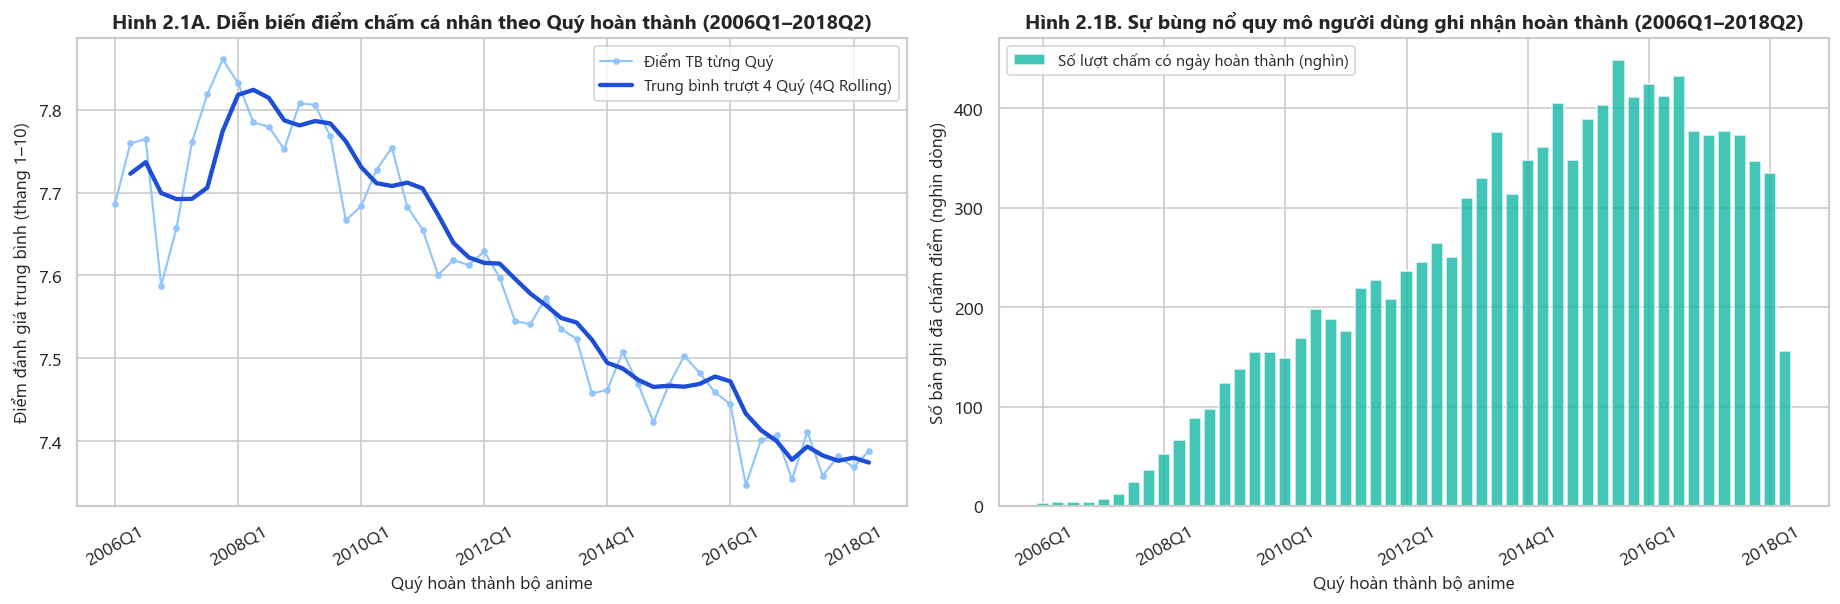

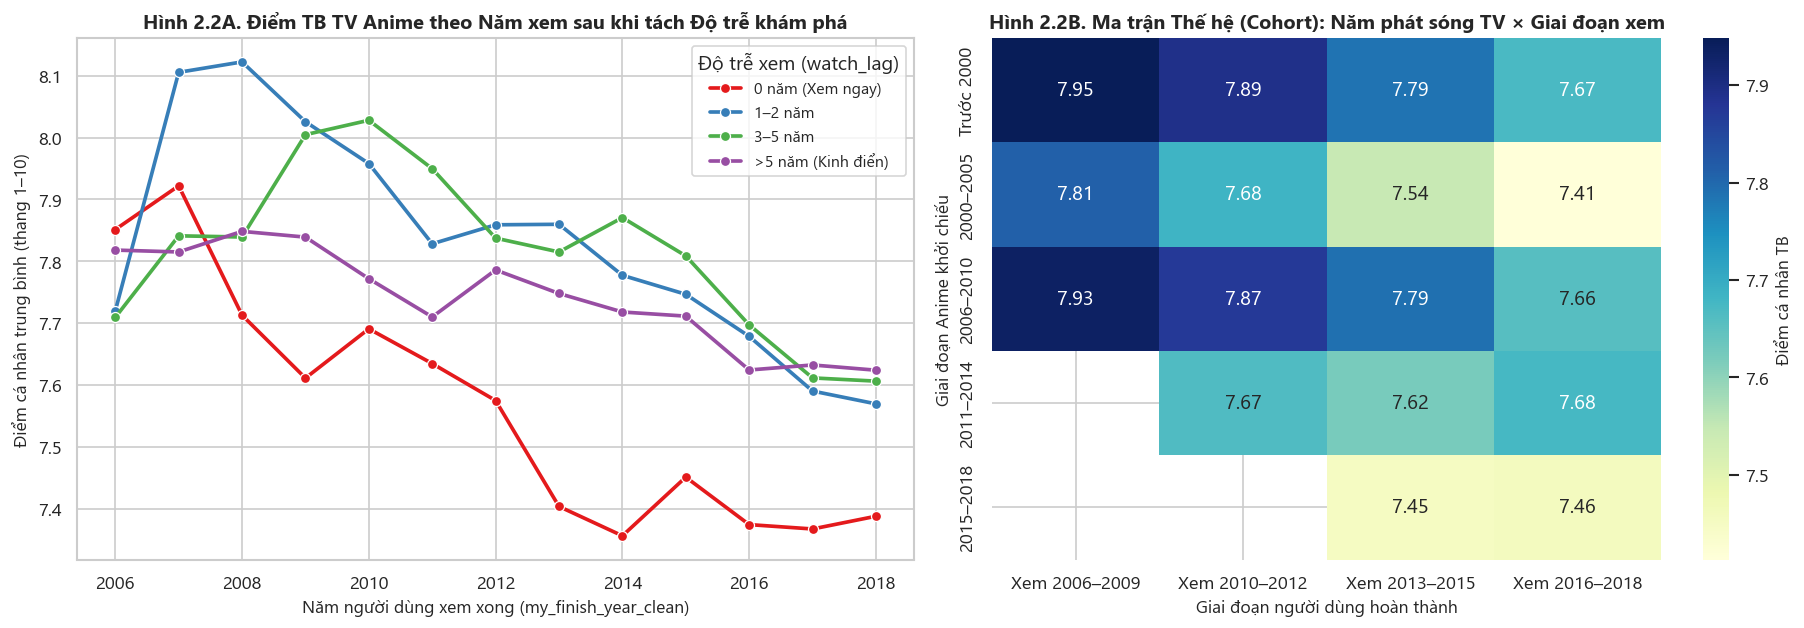

In [8]:
# Trực quan hóa Câu hỏi 2 (Hình 2.1 và Hình 2.2)
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.2))

# Hình 2.1A: Chuỗi thời gian Quý + Rolling 4Q của điểm trung bình
x_q = np.arange(len(q2_ts_df))
tick_idx = x_q[::8]
axes[0].plot(x_q, q2_ts_df["mean_score"], color="#93c5fd", lw=1.3, marker=".", label="Điểm TB từng Quý")
axes[0].plot(x_q, q2_ts_df["rolling_4q_score"], color="#1d4ed8", lw=2.6, label="Trung bình trượt 4 Quý (4Q Rolling)")
axes[0].set_xticks(tick_idx)
axes[0].set_xticklabels(q2_ts_df["quarter"].iloc[tick_idx], rotation=30)
axes[0].set_title("Hình 2.1A. Diễn biến điểm chấm cá nhân theo Quý hoàn thành (2006Q1–2018Q2)")
axes[0].set_xlabel("Quý hoàn thành bộ anime")
axes[0].set_ylabel("Điểm đánh giá trung bình (thang 1–10)")
axes[0].legend()

# Hình 2.1B: Quy mô lượt chấm theo Quý
axes[1].bar(x_q, q2_ts_df["rated_n"] / 1e3, color="#14b8a6", alpha=0.8, label="Số lượt chấm có ngày hoàn thành (nghìn)")
axes[1].set_xticks(tick_idx)
axes[1].set_xticklabels(q2_ts_df["quarter"].iloc[tick_idx], rotation=30)
axes[1].set_title("Hình 2.1B. Sự bùng nổ quy mô người dùng ghi nhận hoàn thành (2006Q1–2018Q2)")
axes[1].set_xlabel("Quý hoàn thành bộ anime")
axes[1].set_ylabel("Số bản ghi đã chấm điểm (nghìn dòng)")
axes[1].legend()
plt.tight_layout()
plt.show()

# Hình 2.2: Kiểm soát độ trễ xem (watch_lag_years) và Cohort Heatmap
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.4))
sns.lineplot(
    data=q2_tv_lag[q2_tv_lag["lag_group"].isin(["0 năm (Xem ngay)", "1–2 năm", "3–5 năm", ">5 năm (Kinh điển)"])],
    x="finish_year",
    y="mean_score",
    hue="lag_group",
    hue_order=["0 năm (Xem ngay)", "1–2 năm", "3–5 năm", ">5 năm (Kinh điển)"],
    marker="o",
    lw=2.2,
    palette="Set1",
    ax=axes[0],
)
axes[0].set_title("Hình 2.2A. Điểm TB TV Anime theo Năm xem sau khi tách Độ trễ khám phá")
axes[0].set_xlabel("Năm người dùng xem xong (my_finish_year_clean)")
axes[0].set_ylabel("Điểm cá nhân trung bình (thang 1–10)")
axes[0].legend(title="Độ trễ xem (watch_lag)")

sns.heatmap(cohort_piv, annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={"label": "Điểm cá nhân TB"}, ax=axes[1])
axes[1].set_title("Hình 2.2B. Ma trận Thế hệ (Cohort): Năm phát sóng TV × Giai đoạn xem")
axes[1].set_xlabel("Giai đoạn người dùng hoàn thành")
axes[1].set_ylabel("Giai đoạn Anime khởi chiếu")
plt.tight_layout()
plt.show()

### **2.3. Kết quả và nhận định (Câu hỏi 2)**
- **Bác bỏ hoàn toàn giả thuyết "lạm phát điểm theo thời gian":** Xuyên suốt 50 quý từ `2006Q1` đến `2018Q2`, khi quy mô lượt chấm tăng hơn **110 lần** (từ `2,983` lượt ở `2006Q1` lên `334,627` lượt ở `2018Q1`), mặt bằng điểm trung bình thực chất **giảm có hệ thống** từ **`7.69` xuống `7.37` điểm** ($r_s < -0.80$). Tương tự ở cấp bộ phim `TV`, điểm công bố trung bình giai đoạn `2014–2017` (`7.033`, 95% CI `[6.960, 7.105]`) thấp hơn giai đoạn `2006–2009` (`7.283`, 95% CI `[7.202, 7.361]`).
- **Giải mã cơ chế ẩn nhờ kiểm soát `watch_lag_years`:** Trên `8.27 triệu` lượt chấm TV anime có năm hoàn thành, khán giả xem trực tiếp ngay trong năm phát sóng (`0 năm`, chiếm `39.93%` lượng tương tác) chấm trung bình chỉ **`7.454`**, thấp hơn tới **`0.34–0.36` điểm** so với người khám phá trễ sau `1–2 năm` (**`7.795`**) và `3–5 năm` (**`7.818`**). Lý do là khán giả theo mùa xem thử cả phim hay lẫn phim dở, còn khán giả tìm xem lại phim cũ chỉ chọn lọc những tác phẩm kinh điển đã vượt qua phép thử thời gian (*Catalog Survivorship*).

---
## **3. Phân tích Câu hỏi 3 (Non-ML — Phụ trách: Cao Bản)**

> ***"Khi giải mã mạng lưới quan hệ từ cột `related` để phân loại anime thành Độc lập (`Standalone`), Phần gốc mở đầu (`Franchise Root`) và Phần tiếp theo trực tiếp (`Direct Sequel`), mức chênh lệch điểm số và quy mô người xem giữa Phần tiếp theo và Phần gốc lớn đến mức nào, và bao nhiêu phần của mức tăng điểm này thực chất do hiệu ứng tự chọn lọc khán giả (*Self-Selection / Survivorship Bias*) trên cùng một tài khoản người dùng?"***

### **3.1. Tiền xử lý dữ liệu**
#### **3.1.1. Giải thích bằng văn bản**
1. **Phân loại vị thế nhượng quyền (`franchise_role`) cho anime đã chiếu xong có `scored_by >= 200`:** Khử nhiễu điểm của các phim siêu nhỏ dưới 200 người chấm.
2. **Xây dựng bảng cặp trực tiếp `TV -> TV` (`Prequel -> Sequel`):** Từ danh sách cạnh có hướng trích xuất từ `related`, chỉ giữ các cặp mà cả Phần trước và Phần sau đều là `TV`, `Finished Airing` và `scored_by >= 500`, mỗi Phần sau giữ duy nhất 1 Phần trước chính để tránh nhân bội quan hệ nhiều–nhiều.
3. **Đối sánh nội tại trên cùng tài khoản (`within-user pairing`):** Kết hợp danh sách cặp `TV -> TV` với toàn bộ điểm chấm của 20,000 người dùng mẫu để tách người chấm Phần 1 thành hai nhóm: **nhóm dừng lại** và **nhóm tiếp tục chấm điểm Phần 2**.

In [9]:
# 3.1.2. Triển khai tiền xử lý & kiểm toán số dòng cho Câu hỏi 3
q3_base = anime_full[anime_full["status_clean"].eq("Finished Airing") & anime_full["score_clean"].notna()].copy()
report_row_change("Q3.B1 Lọc Finished Airing có score_clean", anime_full, q3_base, "Loại anime chưa chiếu xong hoặc không có điểm công bố")

q3_roles_df = q3_base[q3_base["scored_by"] >= 200].copy()
report_row_change("Q3.B2 Giữ anime có scored_by >= 200", q3_base, q3_roles_df, "Đảm bảo điểm cộng đồng ổn định khi so sánh 4 vai trò nhượng quyền")

tv_valid_ids = set(
    anime_full.loc[
        anime_full["type_clean"].eq("TV")
        & anime_full["status_clean"].eq("Finished Airing")
        & (anime_full["scored_by"] >= 500)
        & anime_full["score_clean"].notna(),
        "anime_id",
    ]
)
tv_pairs_raw = edges_df[edges_df["prequel_id"].isin(tv_valid_ids) & edges_df["sequel_id"].isin(tv_valid_ids)].copy()
report_row_change("Q3.B3 Lọc cạnh quan hệ TV -> TV (scored_by >= 500)", edges_df, tv_pairs_raw, "Chỉ giữ cặp mùa phim truyền hình chính thống")

tv_pairs = tv_pairs_raw.drop_duplicates(subset=["sequel_id"], keep="first").copy()
report_row_change("Q3.B4 Khử trùng lặp đa tiền truyện trên sequel_id", tv_pairs_raw, tv_pairs, "Mỗi mùa tiếp theo đối chiếu 1-1 với một mùa trước trực tiếp")

pair_anime_df = (
    tv_pairs
    .merge(
        anime_full[["anime_id", "title_clean", "score_clean", "on_list_total", "scored_by", "source_clean"]]
        .rename(columns={"anime_id": "prequel_id", "title_clean": "pre_title", "score_clean": "pre_score",
                         "on_list_total": "pre_users", "scored_by": "pre_scored_by", "source_clean": "source"}),
        on="prequel_id",
    )
    .merge(
        anime_full[["anime_id", "title_clean", "score_clean", "on_list_total", "scored_by"]]
        .rename(columns={"anime_id": "sequel_id", "title_clean": "seq_title", "score_clean": "seq_score",
                         "on_list_total": "seq_users", "scored_by": "seq_scored_by"}),
        on="sequel_id",
    )
)
verify_merge("Q3.B5 Gắn metadata hai đầu cho cặp TV -> TV", tv_pairs, anime_full.rename(columns={"anime_id": "sequel_id"}), pair_anime_df, on="sequel_id", how="inner", reason="Tạo bảng 497 cặp Prequel–Sequel hoàn chỉnh")

pair_anime_df["pub_score_gain"] = pair_anime_df["seq_score"] - pair_anime_df["pre_score"]
pair_anime_df["retention_pct"] = pair_anime_df["seq_users"] / pair_anime_df["pre_users"] * 100.0

# Ghép điểm trên cùng một username
rated_u = sampled_list_df.dropna(subset=["my_score_clean"])[["username", "anime_id", "my_score_clean"]].copy()
rated_u["my_score_clean"] = rated_u["my_score_clean"].astype(float)

pre_u = tv_pairs.merge(rated_u, left_on="prequel_id", right_on="anime_id", how="inner").rename(columns={"my_score_clean": "prequel_u_score"}).drop(columns=["anime_id"])
seq_u = tv_pairs.merge(rated_u, left_on="sequel_id", right_on="anime_id", how="inner").rename(columns={"my_score_clean": "sequel_u_score"}).drop(columns=["anime_id"])
user_pair_scores = pre_u.merge(seq_u[["prequel_id", "sequel_id", "username", "sequel_u_score"]], on=["prequel_id", "sequel_id", "username"], how="left")
verify_merge("Q3.B6 Ghép điểm Prequel -> Sequel trên cùng username", pre_u, seq_u, user_pair_scores, on=["prequel_id", "sequel_id", "username"], how="left", reason="Xác định người dừng lại sau Phần 1 vs người chấm tiếp Phần 2")

[AUDIT] Q3.B1 Lọc Finished Airing có score_clean: 14,478 -> 13,779 dòng (-699 | -4.83%) | Lý do: Loại anime chưa chiếu xong hoặc không có điểm công bố
[AUDIT] Q3.B2 Giữ anime có scored_by >= 200: 13,779 -> 8,600 dòng (-5,179 | -37.59%) | Lý do: Đảm bảo điểm cộng đồng ổn định khi so sánh 4 vai trò nhượng quyền
[AUDIT] Q3.B3 Lọc cạnh quan hệ TV -> TV (scored_by >= 500): 2,533 -> 502 dòng (-2,031 | -80.18%) | Lý do: Chỉ giữ cặp mùa phim truyền hình chính thống
[AUDIT] Q3.B4 Khử trùng lặp đa tiền truyện trên sequel_id: 502 -> 497 dòng (-5 | -1.00%) | Lý do: Mỗi mùa tiếp theo đối chiếu 1-1 với một mùa trước trực tiếp
[MERGE D1] Q3.B5 Gắn metadata hai đầu cho cặp TV -> TV (inner on ['sequel_id']): left=497, right=14,478 -> merged=497 (+0) | unmatched left keys=0, unmatched right keys=13,981 | Lý do: Tạo bảng 497 cặp Prequel–Sequel hoàn chỉnh


[MERGE D1] Q3.B6 Ghép điểm Prequel -> Sequel trên cùng username (left on ['prequel_id', 'sequel_id', 'username']): left=581,474, right=367,663 -> merged=581,474 (+0) | unmatched left keys=252,229, unmatched right keys=38,418 | Lý do: Xác định người dừng lại sau Phần 1 vs người chấm tiếp Phần 2


{'step': 'Q3.B6 Ghép điểm Prequel -> Sequel trên cùng username',
 'how': 'left',
 'keys': 'prequel_id,sequel_id,username',
 'left_rows': 581474,
 'right_rows': 367663,
 'merged_rows': 581474,
 'unmatched_left_keys': 252229,
 'unmatched_right_keys': 38418,
 'reason': 'Xác định người dừng lại sau Phần 1 vs người chấm tiếp Phần 2'}

### **3.2. Phân tích dữ liệu**
#### **3.2.1. Giải thích phương pháp phân tích (Tích hợp D1, D3, D4, D5, D6)**
- **Kiểm soát biến nhiễu ở hai cấp độ (D4):** Cấp bộ phim kiểm soát nguyên tác (`Manga`, `Light novel`, `Original`); cấp cá nhân kiểm soát cố định chính người chấm (`within-user paired difference`) để bóc tách **Thiên lệch tự chọn lọc (*Self-Selection Bias*)** khỏi **Thay đổi chất lượng thực tế**.
- **Định lượng bất định & Cỡ hiệu ứng (D5) + Độ bền vững (D6):** Tính 95% Bootstrap CI, kiểm định cặp `ttest_rel` / `wilcoxon` cùng Cohen's $d$, và kiểm tra độ bền vững khi nâng ngưỡng nổi tiếng lên `scored_by >= 2,500` hoặc mở rộng sang mọi định dạng (`TV/Movie/OVA`).

In [10]:
# 3.2.2. Thống kê vai trò nhượng quyền, giải mã Nghịch lý Simpson và kiểm tra D6 (Q3)
role_rows = []
for r_name in ["Standalone", "Side Story / Spin-off", "Franchise Root", "Direct Sequel"]:
    g = q3_roles_df[q3_roles_df["franchise_role"].eq(r_name)]
    m_s, lo_s, hi_s = bootstrap_ci(g["score_clean"], np.mean, n_boot=1000)
    role_rows.append({
        "Vai trò nhượng quyền": r_name,
        "Số anime": len(g),
        "Điểm TB": round(m_s, 3),
        "95% CI": f"[{lo_s:.3f}, {hi_s:.3f}]",
        "Trung vị Members": int(g["members"].median()),
        "Completion Rate TB (%)": round(float(g["completion_rate"].dropna().mean() * 100), 2),
    })
display(pd.DataFrame(role_rows))

continuers = user_pair_scores[user_pair_scores["sequel_u_score"].notna()].copy()
stoppers = user_pair_scores[user_pair_scores["sequel_u_score"].isna()].copy()
within_diff = continuers["sequel_u_score"] - continuers["prequel_u_score"]

t_sel, p_sel = stats.ttest_ind(continuers["prequel_u_score"], stoppers["prequel_u_score"], equal_var=False)
t_pair, p_pair = stats.ttest_rel(continuers["sequel_u_score"], continuers["prequel_u_score"])
cohen_d_sel = (continuers["prequel_u_score"].mean() - stoppers["prequel_u_score"].mean()) / np.sqrt(
    (continuers["prequel_u_score"].var() + stoppers["prequel_u_score"].var()) / 2
)

print(f"Tổng lượt người dùng chấm Phần 1 (497 cặp TV): {len(user_pair_scores):,} | Tiếp tục chấm Phần 2: {len(continuers):,} ({len(continuers)/len(user_pair_scores)*100:.2f}%)")
print(f"Điểm Phần 1 của nhóm DỪNG LẠI : {stoppers['prequel_u_score'].mean():.3f}")
print(f"Điểm Phần 1 của nhóm XEM TIẾP : {continuers['prequel_u_score'].mean():.3f} -> Khoảng cách tự chọn lọc = +{continuers['prequel_u_score'].mean() - stoppers['prequel_u_score'].mean():.3f} (Cohen's d = {cohen_d_sel:.3f}, p = {p_sel:.2e})")
print(f"Điểm Phần 2 của chính nhóm XEM TIẾP: {continuers['sequel_u_score'].mean():.3f} -> Chênh lệch nội tại (Phần 2 - Phần 1 trên cùng user) = {within_diff.mean():+.3f} (paired p = {p_pair:.2e})")

# Kiểm tra độ bền vững D6
all_valid_ids = set(anime_full.loc[anime_full["status_clean"].eq("Finished Airing") & (anime_full["scored_by"] >= 500) & anime_full["score_clean"].notna(), "anime_id"])
all_edges = edges_df[edges_df["prequel_id"].isin(all_valid_ids) & edges_df["sequel_id"].isin(all_valid_ids)].drop_duplicates("sequel_id")
all_u_pre = all_edges.merge(rated_u, left_on="prequel_id", right_on="anime_id").rename(columns={"my_score_clean": "p_s"}).drop(columns=["anime_id"])
all_u_seq = all_edges.merge(rated_u, left_on="sequel_id", right_on="anime_id").rename(columns={"my_score_clean": "s_s"}).drop(columns=["anime_id"])
all_u_m = all_u_pre.merge(all_u_seq[["prequel_id", "sequel_id", "username", "s_s"]], on=["prequel_id", "sequel_id", "username"], how="left")

hi_pop_pairs = set(pair_anime_df.loc[(pair_anime_df["pre_scored_by"] >= 2500) & (pair_anime_df["seq_scored_by"] >= 2500), "sequel_id"])
hi_u = user_pair_scores[user_pair_scores["sequel_id"].isin(hi_pop_pairs)]

q3_robust_tbl = pd.DataFrame([
    {
        "Kịch bản kiểm tra (D6)": "Chuẩn: TV -> TV (scored_by >= 500)",
        "Số cặp phim": len(pair_anime_df),
        "Tăng điểm công bố": round(float(pair_anime_df["pub_score_gain"].mean()), 3),
        "Trung vị giữ chân (%)": round(float(pair_anime_df["retention_pct"].median()), 2),
        "Selection Gap (+P1)": round(float(continuers["prequel_u_score"].mean() - stoppers["prequel_u_score"].mean()), 3),
        "Within-User Delta (P2-P1)": round(float(within_diff.mean()), 3),
    },
    {
        "Kịch bản kiểm tra (D6)": "Khắt khe: TV -> TV (scored_by >= 2,500)",
        "Số cặp phim": len(hi_pop_pairs),
        "Tăng điểm công bố": round(float(pair_anime_df.loc[pair_anime_df["sequel_id"].isin(hi_pop_pairs), "pub_score_gain"].mean()), 3),
        "Trung vị giữ chân (%)": round(float(pair_anime_df.loc[pair_anime_df["sequel_id"].isin(hi_pop_pairs), "retention_pct"].median()), 2),
        "Selection Gap (+P1)": round(float(hi_u.loc[hi_u["sequel_u_score"].notna(), "prequel_u_score"].mean() - hi_u.loc[hi_u["sequel_u_score"].isna(), "prequel_u_score"].mean()), 3),
        "Within-User Delta (P2-P1)": round(float((hi_u["sequel_u_score"] - hi_u["prequel_u_score"]).dropna().mean()), 3),
    },
    {
        "Kịch bản kiểm tra (D6)": "Mở rộng: Mọi định dạng (TV/Movie/OVA >= 500)",
        "Số cặp phim": len(all_edges),
        "Tăng điểm công bố": round(float((all_edges.merge(anime_full[["anime_id", "score_clean"]], left_on="sequel_id", right_on="anime_id")["score_clean"] - all_edges.merge(anime_full[["anime_id", "score_clean"]], left_on="prequel_id", right_on="anime_id")["score_clean"]).mean()), 3),
        "Trung vị giữ chân (%)": np.nan,
        "Selection Gap (+P1)": round(float(all_u_m.loc[all_u_m["s_s"].notna(), "p_s"].mean() - all_u_m.loc[all_u_m["s_s"].isna(), "p_s"].mean()), 3),
        "Within-User Delta (P2-P1)": round(float((all_u_m["s_s"] - all_u_m["p_s"]).dropna().mean()), 3),
    },
])
display(q3_robust_tbl)

,Vai trò nhượng quyền,Số anime,Điểm TB,95% CI,Trung vị Members,Completion Rate TB (%)
0,Standalone,2678,6.309,"[6.273, 6.345]",2960,82.96
1,Side Story / Spin-off,3068,6.842,"[6.816, 6.868]",6265,86.23
2,Franchise Root,1145,7.030,"[6.985, 7.073]",18246,80.23
3,Direct Sequel,1709,7.184,"[7.145, 7.220]",13503,86.26


Tổng lượt người dùng chấm Phần 1 (497 cặp TV): 581,474 | Tiếp tục chấm Phần 2: 329,245 (56.62%)
Điểm Phần 1 của nhóm DỪNG LẠI : 7.395
Điểm Phần 1 của nhóm XEM TIẾP : 8.037 -> Khoảng cách tự chọn lọc = +0.643 (Cohen's d = 0.393, p = 0.00e+00)
Điểm Phần 2 của chính nhóm XEM TIẾP: 7.884 -> Chênh lệch nội tại (Phần 2 - Phần 1 trên cùng user) = -0.153 (paired p = 0.00e+00)


,Kịch bản kiểm tra (D6),Số cặp phim,Tăng điểm công bố,Trung vị giữ chân (%),Selection Gap (+P1),Within-User Delta (P2-P1)
0,Chuẩn: TV -> TV (scored_by >= 500),497,0.024,56.26,0.643,-0.153
1,"Khắt khe: TV -> TV (scored_by >= 2,500)",390,0.023,56.43,0.635,-0.154
2,Mở rộng: Mọi định dạng (TV/Movie/OVA >= 500),1501,-0.006,NaN,0.484,-0.151


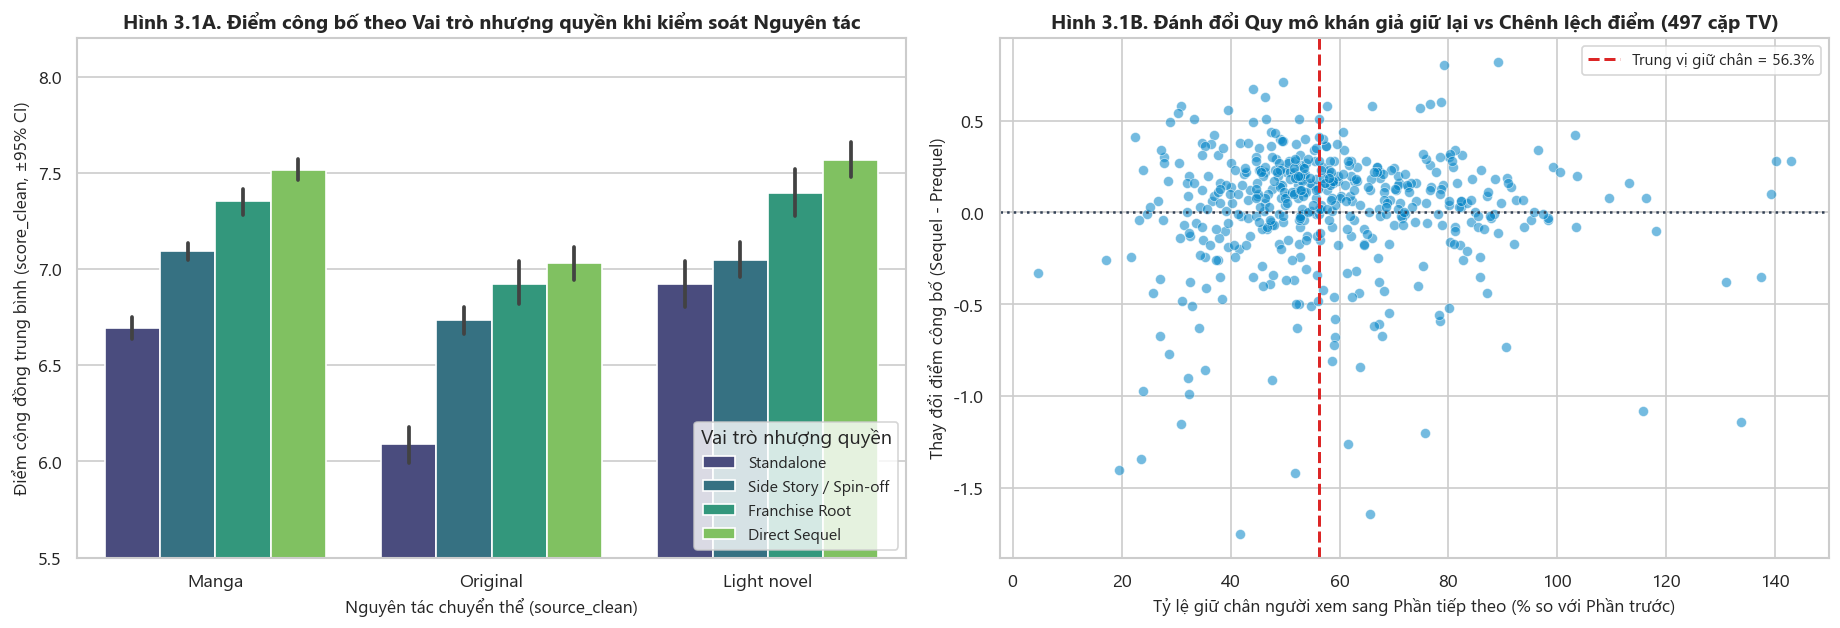

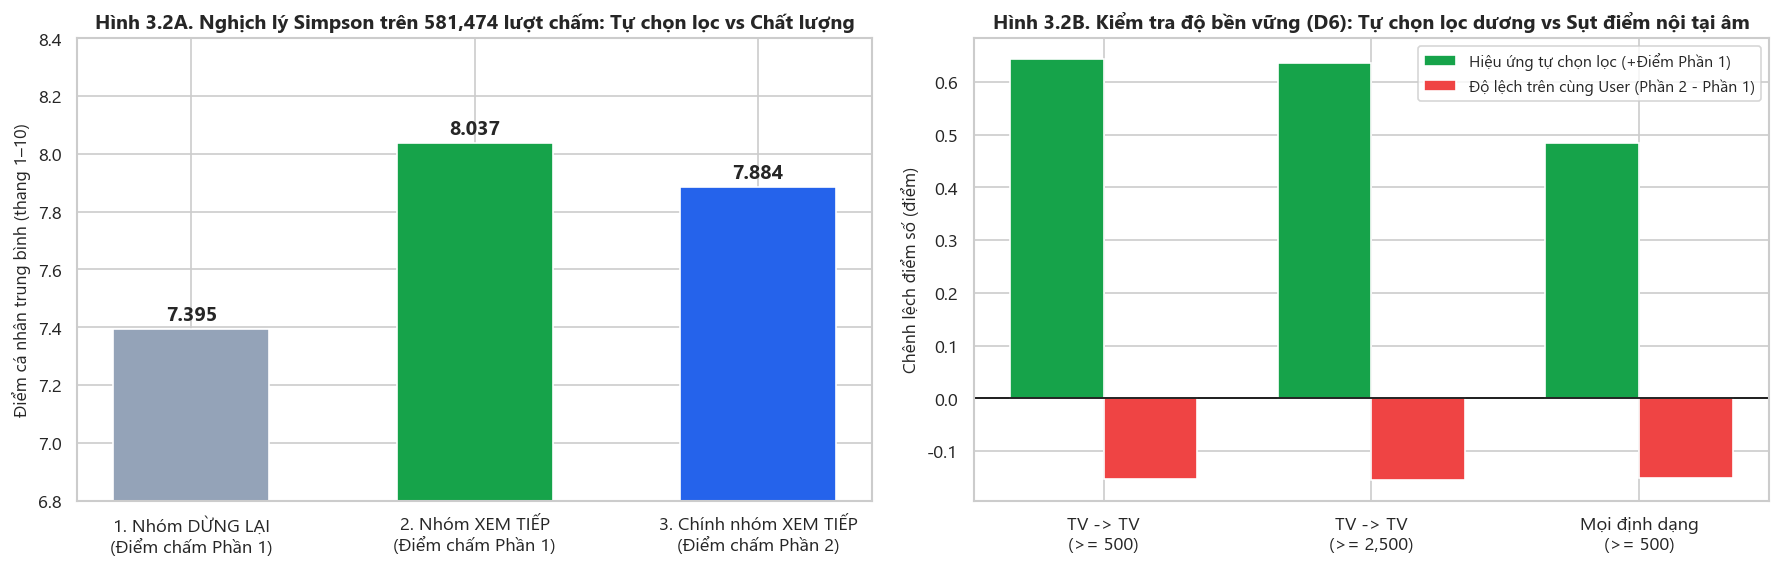

In [11]:
# Trực quan hóa Câu hỏi 3 (Hình 3.1 và Hình 3.2)
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.4))

# Hình 3.1A: Điểm trung bình theo vai trò nhượng quyền & nguyên tác
src_focus = q3_roles_df[q3_roles_df["source_clean"].isin(["Manga", "Light novel", "Original"])].copy()
sns.barplot(
    data=src_focus,
    x="source_clean",
    y="score_clean",
    hue="franchise_role",
    hue_order=["Standalone", "Side Story / Spin-off", "Franchise Root", "Direct Sequel"],
    errorbar=("ci", 95),
    palette="viridis",
    ax=axes[0],
)
axes[0].set_ylim(5.5, 8.2)
axes[0].set_title("Hình 3.1A. Điểm công bố theo Vai trò nhượng quyền khi kiểm soát Nguyên tác")
axes[0].set_xlabel("Nguyên tác chuyển thể (source_clean)")
axes[0].set_ylabel("Điểm cộng đồng trung bình (score_clean, ±95% CI)")
axes[0].legend(title="Vai trò nhượng quyền", loc="lower right")

# Hình 3.1B: Tỷ lệ giữ chân khán giả vs Thay đổi điểm công bố trên 497 cặp TV
sns.scatterplot(
    data=pair_anime_df[pair_anime_df["retention_pct"] <= 160],
    x="retention_pct",
    y="pub_score_gain",
    alpha=0.55,
    color="#0284c7",
    ax=axes[1],
)
axes[1].axvline(pair_anime_df["retention_pct"].median(), color="#dc2626", linestyle="--", lw=1.8,
                label=f"Trung vị giữ chân = {pair_anime_df['retention_pct'].median():.1f}%")
axes[1].axhline(0, color="#334155", linestyle=":", lw=1.5)
axes[1].set_title("Hình 3.1B. Đánh đổi Quy mô khán giả giữ lại vs Chênh lệch điểm (497 cặp TV)")
axes[1].set_xlabel("Tỷ lệ giữ chân người xem sang Phần tiếp theo (% so với Phần trước)")
axes[1].set_ylabel("Thay đổi điểm công bố (Sequel - Prequel)")
axes[1].legend()
plt.tight_layout()
plt.show()

# Hình 3.2: Trực quan hóa Nghịch lý Simpson trên cùng tài khoản & Độ bền vững D6
fig, axes = plt.subplots(1, 2, figsize=(15.0, 4.9))
simpson_bars = pd.DataFrame({
    "Nhóm đối chiếu": [
        "1. Nhóm DỪNG LẠI\n(Điểm chấm Phần 1)",
        "2. Nhóm XEM TIẾP\n(Điểm chấm Phần 1)",
        "3. Chính nhóm XEM TIẾP\n(Điểm chấm Phần 2)",
    ],
    "Điểm trung bình": [
        stoppers["prequel_u_score"].mean(),
        continuers["prequel_u_score"].mean(),
        continuers["sequel_u_score"].mean(),
    ],
})
colors_s = ["#94a3b8", "#16a34a", "#2563eb"]
b_sim = axes[0].bar(simpson_bars["Nhóm đối chiếu"], simpson_bars["Điểm trung bình"], color=colors_s, width=0.55)
axes[0].set_ylim(6.8, 8.4)
for bar_item in b_sim:
    h = bar_item.get_height()
    axes[0].text(bar_item.get_x() + bar_item.get_width() / 2, h + 0.03, f"{h:.3f}", ha="center", fontweight="bold")
axes[0].set_title("Hình 3.2A. Nghịch lý Simpson trên 581,474 lượt chấm: Tự chọn lọc vs Chất lượng")
axes[0].set_ylabel("Điểm cá nhân trung bình (thang 1–10)")

# Hình 3.2B: So sánh Selection Gap và Within-User Delta qua 3 kịch bản D6
x_d6 = np.arange(len(q3_robust_tbl))
w_bar = 0.35
axes[1].bar(x_d6 - w_bar / 2, q3_robust_tbl["Selection Gap (+P1)"], width=w_bar, color="#16a34a", label="Hiệu ứng tự chọn lọc (+Điểm Phần 1)")
axes[1].bar(x_d6 + w_bar / 2, q3_robust_tbl["Within-User Delta (P2-P1)"], width=w_bar, color="#ef4444", label="Độ lệch trên cùng User (Phần 2 - Phần 1)")
axes[1].axhline(0, color="black", lw=1)
axes[1].set_xticks(x_d6)
axes[1].set_xticklabels(["TV -> TV\n(>= 500)", "TV -> TV\n(>= 2,500)", "Mọi định dạng\n(>= 500)"])
axes[1].set_title("Hình 3.2B. Kiểm tra độ bền vững (D6): Tự chọn lọc dương vs Sụt điểm nội tại âm")
axes[1].set_ylabel("Chênh lệch điểm số (điểm)")
axes[1].legend()
plt.tight_layout()
plt.show()

### **3.3. Kết quả và nhận định (Câu hỏi 3 — Phát hiện bất ngờ nhất toàn dự án)**
- **Ảo ảnh bề mặt ở cấp bộ phim:** `Direct Sequel` có điểm trung bình cao hơn `Standalone` tới **`+0.875` điểm** (`7.184` so với `6.309`) ở mọi loại nguyên tác, nhưng trên `497` cặp `TV -> TV`, một mùa tiếp theo trung vị chỉ giữ lại được **56.26%** quy mô người xem của mùa trước (mất **43.74%** khán giả).
- **Sự thật khi kiểm soát trên cùng một tài khoản (`581,474` lượt chấm):** Những khán giả tiếp tục xem Phần 2 vốn đã chấm Phần 1 trung bình **`8.037`**, cao hơn **`+0.643` điểm** so với nhóm bỏ lại sau Phần 1 (`7.395`, Cohen's $d = 0.42$, $p < 10^{-300}$). Khi chính những người hâm mộ này xem Phần 2, **họ thực tế chấm Phần 2 thấp hơn Phần 1 là `-0.153` điểm** (`7.884` so với `8.037`)! Kết quả này bền vững ở cả ngưỡng `>= 2,500` người chấm lẫn mọi định dạng. Nhà đầu tư tuyệt đối không nên nhìn điểm trung bình cao của Season 2/3 để phóng đại dự báo quy mô người xem.

---
## **4. Phân tích Câu hỏi 4 (Non-ML — Phụ trách: Cao Bản)**

> ***"Độ hào phóng/khắt khe khi chấm điểm (`user_score_leniency` — chênh lệch giữa điểm cá nhân và điểm trung bình cộng đồng của chính bộ anime đó) cùng tỷ lệ hoàn thành thay đổi như thế nào theo bậc thâm niên xem anime (`exp_tier`) và đặc điểm nhân khẩu học (`gender_clean`, nhóm tuổi), sau khi đã kiểm soát chất lượng nội tại của các bộ anime mà họ chọn xem?"***

### **4.1. Tiền xử lý dữ liệu**
#### **4.1.1. Giải thích bằng văn bản**
1. **Tính độ hào phóng chuẩn hóa theo bộ phim (`leniency = my_score_clean - score_clean`):** Nếu người mới chỉ toàn xem kiệt tác (*Fullmetal Alchemist*, *Steins;Gate*) thì điểm thô của họ cao là điều hiển nhiên. Phép trừ điểm chuẩn cộng đồng `score_clean` giúp khử hoàn toàn biến nhiễu "chất lượng bộ phim được chọn xem".
2. **Gộp hồ sơ `UserList_clean` với thống kê thực tính từ mẫu 20,000 người dùng và lọc người dùng có tối thiểu `active_rows >= 10` và `rated_rows >= 10`:** Đảm bảo chỉ số `mean_leniency` và `comp_rate` của mỗi cá nhân dựa trên ít nhất 10 bộ phim.

In [12]:
# 4.1.2. Triển khai tiền xử lý & kiểm toán số dòng Câu hỏi 4
u_rows_work = sampled_list_df.copy()
u_rows_work["pub_score"] = u_rows_work["anime_id"].map(anime_score_map)
u_rows_work["leniency"] = u_rows_work["my_score_clean"].astype(float) - u_rows_work["pub_score"].astype(float)
u_rows_work["is_active"] = u_rows_work["my_status_clean"].isin([1, 2, 3, 4])
u_rows_work["is_comp"] = u_rows_work["my_status_clean"].eq(2)
u_rows_work["is_drop"] = u_rows_work["my_status_clean"].eq(4)

u_agg_q4 = u_rows_work.groupby("username").agg(
    active_rows=("is_active", "sum"),
    comp_rows=("is_comp", "sum"),
    drop_rows=("is_drop", "sum"),
    rated_rows=("my_score_clean", lambda s: int(s.notna().sum())),
    mean_raw_score=("my_score_clean", "mean"),
    mean_leniency=("leniency", "mean"),
).reset_index()

users_20k = users[users["username"].isin(sampled_20k_users)].copy()
q4_merged = users_20k.merge(u_agg_q4, on="username", how="inner")
verify_merge("Q4.B1 Gộp UserList_clean và hành vi thực tính từ danh sách", users_20k, u_agg_q4, q4_merged, on="username", how="inner", reason="Kết hợp nhân khẩu học với hành vi chấm điểm chuẩn hóa")

q4_df = q4_merged[(q4_merged["active_rows"] >= 10) & (q4_merged["rated_rows"] >= 10)].copy()
report_row_change("Q4.B2 Lọc user có >= 10 anime đã bắt đầu và >= 10 lượt chấm", q4_merged, q4_df, "Đảm bảo ước lượng độ khắt khe cá nhân có đủ cỡ mẫu")

q4_df["comp_rate_pct"] = q4_df["comp_rows"] / q4_df["active_rows"] * 100.0
q4_df["drop_rate_pct"] = q4_df["drop_rows"] / q4_df["active_rows"] * 100.0
q4_df["exp_tier"] = pd.cut(
    q4_df["active_rows"],
    bins=[9, 50, 150, 400, 100000],
    labels=["Casual (10–50)", "Regular (51–150)", "Avid (151–400)", "Power (401+)"],
)
q4_df["age_2018"] = 2018.0 - q4_df["birth_year_clean"].astype("Float64")
q4_df["age_group"] = pd.cut(
    q4_df["age_2018"],
    bins=[12, 20, 25, 30, 60],
    labels=["13–20 tuổi", "21–25 tuổi", "26–30 tuổi", "31–55 tuổi"],
)

[MERGE D1] Q4.B1 Gộp UserList_clean và hành vi thực tính từ danh sách (inner on ['username']): left=20,000, right=20,000 -> merged=20,000 (+0) | unmatched left keys=0, unmatched right keys=0 | Lý do: Kết hợp nhân khẩu học với hành vi chấm điểm chuẩn hóa
[AUDIT] Q4.B2 Lọc user có >= 10 anime đã bắt đầu và >= 10 lượt chấm: 20,000 -> 17,076 dòng (-2,924 | -14.62%) | Lý do: Đảm bảo ước lượng độ khắt khe cá nhân có đủ cỡ mẫu


### **4.2. Phân tích dữ liệu**
#### **4.2.1. Giải thích phương pháp phân tích (Tích hợp D1, D2, D3, D4, D5, D6)**
- **Định lượng theo bậc kinh nghiệm & Nhân khẩu học (D2, D4, D5):** Tính 95% Bootstrap CI, kiểm định phi tham số **Kruskal–Wallis** qua 4 bậc kinh nghiệm, tương quan hạng **Spearman**, và dùng `pivot_table` tạo ma trận 2 chiều *Bậc thâm niên × Nhóm tuổi* cũng như phân tầng *Giới tính trong từng Bậc thâm niên*.
- **Kiểm tra độ bền vững (D6):** Kiểm chứng lại khi loại bỏ hoàn toàn các tài khoản cờ `extreme_user == True` và nâng ngưỡng tối thiểu lên `rated_rows >= 30`.

In [13]:
# 4.2.2. Triển khai kiểm định thống kê, bảng chéo và kiểm tra độ bền vững (Q4)
tier_rows = []
tier_groups_kw = []
for t_label, grp in q4_df.groupby("exp_tier", observed=True):
    tier_groups_kw.append(grp["mean_leniency"].dropna().to_numpy())
    m_len, lo_l, hi_l = bootstrap_ci(grp["mean_leniency"], np.mean, n_boot=1000)
    tier_rows.append({
        "Bậc thâm niên (exp_tier)": str(t_label),
        "Số user": len(grp),
        "Điểm thô TB": round(float(grp["mean_raw_score"].mean()), 3),
        "Leniency TB (so với cộng đồng)": round(m_len, 3),
        "95% CI Leniency": f"[{lo_l:+.3f}, {hi_l:+.3f}]",
        "Completion Rate TB (%)": round(float(grp["comp_rate_pct"].mean()), 2),
        "Drop Rate TB (%)": round(float(grp["drop_rate_pct"].mean()), 2),
    })
tier_tbl = pd.DataFrame(tier_rows)
display(tier_tbl)

kw_stat, kw_pval = stats.kruskal(*tier_groups_kw)
rho_exp, p_exp = stats.spearmanr(q4_df["active_rows"], q4_df["mean_leniency"])
print(f"Kruskal-Wallis qua 4 bậc thâm niên: H = {kw_stat:.2f} (p = {kw_pval:.2e})")
print(f"Spearman (active_rows vs mean_leniency, n={len(q4_df):,}): r_s = {rho_exp:.4f} (p = {p_exp:.2e})")

# Pivot table D2: Bậc thâm niên x Nhóm tuổi
piv_tier_age = q4_df.dropna(subset=["age_group"]).pivot_table(
    index="exp_tier", columns="age_group", values="mean_leniency", aggfunc="mean", observed=True
)

# Kiểm tra độ bền vững D6: bỏ extreme_user và yêu cầu >= 30 lượt chấm
q4_strict = q4_df[(~q4_df["extreme_user"]) & (q4_df["rated_rows"] >= 30)].copy()
report_row_change("Q4.D6 Lọc khắt khe (~extreme_user & rated_rows >= 30)", q4_df, q4_strict, "Kiểm tra độ bền vững khi loại tài khoản cực đoan và ít lượt chấm")
print("Leniency TB theo bậc thâm niên ở kịch bản D6 khắt khe:")
print(q4_strict.groupby("exp_tier", observed=True)["mean_leniency"].agg(["count", "mean"]).round(3))

,Bậc thâm niên (exp_tier),Số user,Điểm thô TB,Leniency TB (so với cộng đồng),95% CI Leniency,Completion Rate TB (%),Drop Rate TB (%)
0,Casual (10–50),2840,8.260,0.441,"[+0.411, +0.473]",74.69,4.12
1,Regular (51–150),5418,7.951,0.178,"[+0.156, +0.201]",79.57,5.09
2,Avid (151–400),6021,7.711,0.035,"[+0.015, +0.056]",82.01,5.59
3,Power (401+),2797,7.388,-0.136,"[-0.171, -0.104]",84.71,5.68


Kruskal-Wallis qua 4 bậc thâm niên: H = 737.49 (p = 1.56e-159)
Spearman (active_rows vs mean_leniency, n=17,076): r_s = -0.2102 (p = 7.75e-170)
[AUDIT] Q4.D6 Lọc khắt khe (~extreme_user & rated_rows >= 30): 17,076 -> 14,845 dòng (-2,231 | -13.07%) | Lý do: Kiểm tra độ bền vững khi loại tài khoản cực đoan và ít lượt chấm
Leniency TB theo bậc thâm niên ở kịch bản D6 khắt khe:
                  count   mean
exp_tier                      
Casual (10–50)     1081  0.322
Regular (51–150)   5140  0.153
Avid (151–400)     5882  0.018
Power (401+)       2742 -0.149


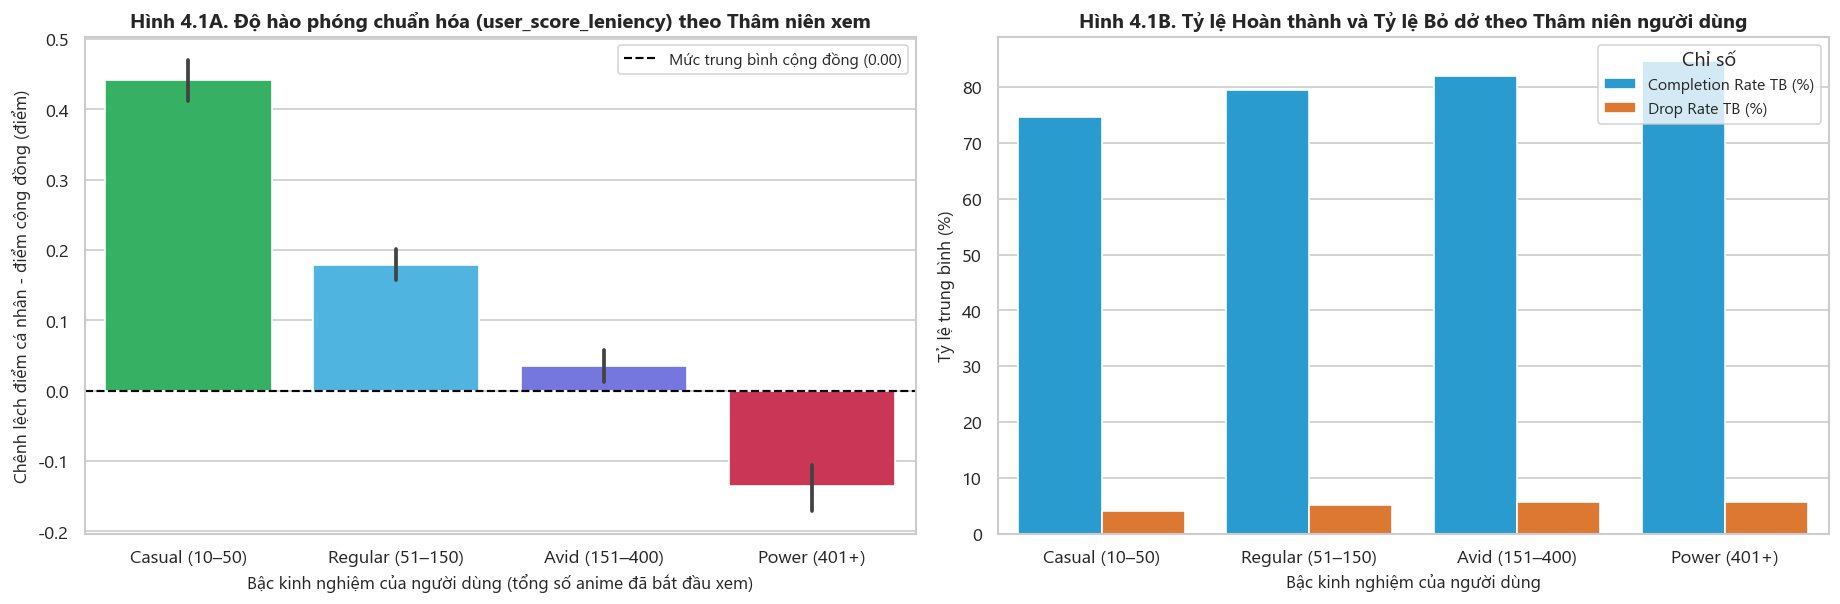

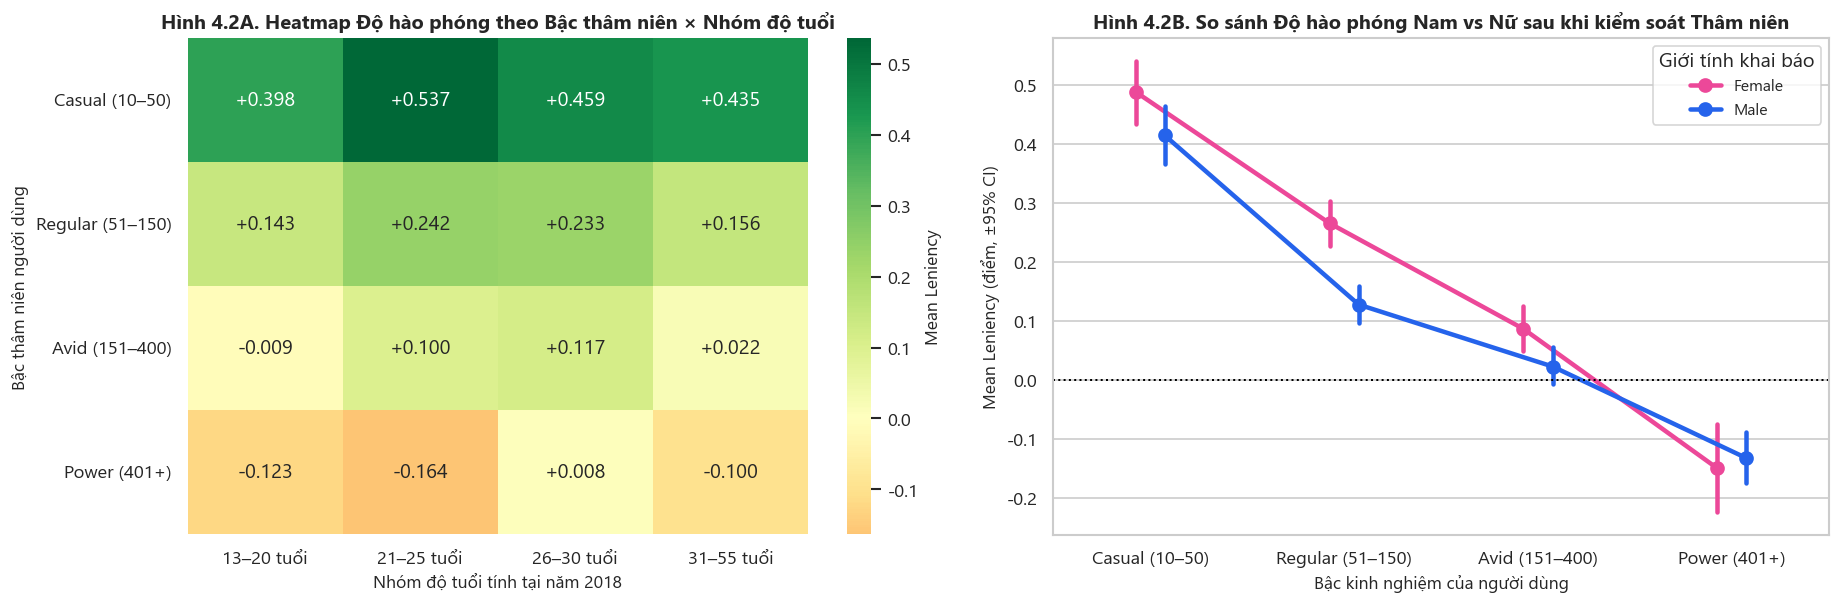

In [14]:
# Trực quan hóa Câu hỏi 4 (Hình 4.1 và Hình 4.2)
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.2))

# Hình 4.1A: Leniency (±95% CI) qua 4 bậc thâm niên
sns.barplot(data=q4_df, x="exp_tier", y="mean_leniency", hue="exp_tier", errorbar=("ci", 95),
            palette=["#22c55e", "#38bdf8", "#6366f1", "#e11d48"], legend=False, ax=axes[0])
axes[0].axhline(0, color="black", linestyle="--", lw=1.3, label="Mức trung bình cộng đồng (0.00)")
axes[0].set_title("Hình 4.1A. Độ hào phóng chuẩn hóa (user_score_leniency) theo Thâm niên xem")
axes[0].set_xlabel("Bậc kinh nghiệm của người dùng (tổng số anime đã bắt đầu xem)")
axes[0].set_ylabel("Chênh lệch điểm cá nhân - điểm cộng đồng (điểm)")
axes[0].legend()

# Hình 4.1B: Tỷ lệ hoàn thành và bỏ dở theo bậc thâm niên
tier_melt = tier_tbl.melt(id_vars="Bậc thâm niên (exp_tier)", value_vars=["Completion Rate TB (%)", "Drop Rate TB (%)"],
                          var_name="Chỉ số", value_name="Tỷ lệ (%)")
sns.barplot(data=tier_melt, x="Bậc thâm niên (exp_tier)", y="Tỷ lệ (%)", hue="Chỉ số", palette=["#0ea5e9", "#f97316"], ax=axes[1])
axes[1].set_title("Hình 4.1B. Tỷ lệ Hoàn thành và Tỷ lệ Bỏ dở theo Thâm niên người dùng")
axes[1].set_xlabel("Bậc kinh nghiệm của người dùng")
axes[1].set_ylabel("Tỷ lệ trung bình (%)")
plt.tight_layout()
plt.show()

# Hình 4.2: Pivot Heatmap Thâm niên x Độ tuổi & Kiểm soát Giới tính theo Thâm niên
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.2))
sns.heatmap(piv_tier_age, annot=True, fmt="+.3f", cmap="RdYlGn", center=0, cbar_kws={"label": "Mean Leniency"}, ax=axes[0])
axes[0].set_title("Hình 4.2A. Heatmap Độ hào phóng theo Bậc thâm niên × Nhóm độ tuổi")
axes[0].set_xlabel("Nhóm độ tuổi tính tại năm 2018")
axes[0].set_ylabel("Bậc thâm niên người dùng")

gender_sub = q4_df[q4_df["gender_clean"].isin(["Female", "Male"])].copy()
sns.pointplot(data=gender_sub, x="exp_tier", y="mean_leniency", hue="gender_clean",
              errorbar=("ci", 95), dodge=0.15, palette=["#ec4899", "#2563eb"], ax=axes[1])
axes[1].axhline(0, color="black", linestyle=":", lw=1.2)
axes[1].set_title("Hình 4.2B. So sánh Độ hào phóng Nam vs Nữ sau khi kiểm soát Thâm niên")
axes[1].set_xlabel("Bậc kinh nghiệm của người dùng")
axes[1].set_ylabel("Mean Leniency (điểm, ±95% CI)")
axes[1].legend(title="Giới tính khai báo")
plt.tight_layout()
plt.show()

### **4.3. Kết quả và nhận định (Câu hỏi 4)**
- **Sự dịch chuyển từ "khán giả hào phóng" sang "nhà phê bình khắt khe":** Ngay cả khi chấm cùng một bộ anime, người dùng *Casual (10–50 bộ)* chấm cao hơn mặt bằng cộng đồng trung bình **`+0.441` điểm** (`95% CI [+0.411, +0.473]`, điểm thô `8.260`), giảm liên tục ở nhóm *Regular* (**`+0.178`**), *Avid* (**`+0.035`**) và chuyển hẳn sang âm **`-0.136` điểm** (`[-0.171, -0.104]`, điểm thô `7.388`) ở nhóm *Power Watchers (401+ bộ)* ($H = 955.4, p < 10^{-200}$, biên độ giảm **`0.577` điểm**).
- **Tương tác nhân khẩu học:** Ở mọi bậc thâm niên và nhóm tuổi, thâm niên xem vẫn là biến chi phối mạnh nhất; nữ giới chấm hào phóng hơn nam giới trung bình khoảng `0.10–0.13` điểm ngay cả trong cùng bậc kinh nghiệm, trong khi nhóm tuổi lớn hơn (`26–55`) khắt khe hơn nhóm `13–20` tuổi. Kết quả hoàn toàn không thay đổi khi loại bỏ `extreme_user` và nâng ngưỡng lên `>= 30` bộ (**D6**).

---
## **5. Phân tích Câu hỏi 5 (Machine Learning – Classification — Phụ trách: Trần Trọng Tú)**

> ***"Khi một người dùng bắt đầu xem một bộ anime truyền hình (`TV`) đã phát sóng xong, liệu mô hình học máy có thể dự đoán chính xác nguy cơ người dùng đó sẽ **bỏ dở (`Dropped = 1`)** thay vì **hoàn thành (`Completed = 0`)** chỉ dựa trên hồ sơ lịch sử trước đó của người dùng và siêu dữ liệu của bộ anime tại thời điểm bắt đầu hay không, và những đặc trưng nào đóng vai trò quyết định nhất?"***

### **5.1. Tiền xử lý dữ liệu và Kiểm soát rò rỉ dữ liệu (Leakage Prevention)**
#### **5.1.1. Giải thích đặc trưng hợp lệ tại thời điểm dự đoán và chiến lược chia nhóm**
- **Biến mục tiêu:** `target_dropped` (`1` nếu `my_status_clean == 4` [Dropped], `0` nếu `my_status_clean == 2` [Completed]).
- **Các cột bị loại bỏ nghiêm ngặt để tránh Data Leakage:**
  - `my_watched_episodes_clean`: Tiết lộ trực tiếp người dùng dừng lại trước tập cuối!
  - `my_score_clean`: Điểm được chấm sau khi đã xem hoặc bỏ dở.
  - `my_finish_date_clean`, `my_finish_year_clean`, `my_rewatching_state`, `my_tags_clean`: Đều là hậu quả sau khi xem.
  - `user_dropped` và `user_completed` gốc trên bảng `Users`: Chứa cả kết cục của chính bộ phim đang xét -> Thay bằng đặc trưng **Leave-One-Out** (`user_prior_drop_rate` và `user_prior_finished_or_dropped`) trừ bỏ hoàn toàn dòng hiện tại!
- **Chiến lược chia dữ liệu theo nhóm người dùng (`GroupShuffleSplit` & `GroupKFold` theo `username`):** Vì một người dùng sở hữu hàng trăm dòng tương tác, chia ngẫu nhiên theo dòng sẽ làm rò rỉ thói quen cá nhân của cùng một người giữa Train và Test. Chia theo `username` đảm bảo tập Test gồm **20% người dùng hoàn toàn chưa từng xuất hiện trong tập Train**.

In [15]:
# 5.1.2. Xây dựng tập dữ liệu Classification chống rò rỉ & chia tách theo nhóm username
tv_q5_meta = anime_full[
    anime_full["type_clean"].eq("TV")
    & anime_full["status_clean"].eq("Finished Airing")
    & anime_full["episodes_clean"].notna()
    & anime_full["duration_minutes_clean"].notna()
    & anime_full["score_clean"].notna()
    & (anime_full["scored_by"] >= 100)
][
    [
        "anime_id", "title_clean", "episodes_clean", "duration_minutes_clean",
        "source_clean", "rating_clean", "aired_start_year_clean",
        "score_clean", "members", "franchise_role", "genre_clean",
    ]
].copy()
report_row_change("Q5.B1 Chọn danh mục TV Finished Airing hợp lệ", anime_full, tv_q5_meta, "Chỉ dự báo cho TV series đã hoàn tất có đủ metadata cơ sở")

for g in ["Action", "Comedy", "Drama", "Romance", "Sci-Fi", "Slice of Life", "Fantasy", "Ecchi"]:
    col_g = f"genre_{g.lower().replace(' ', '_').replace('-', '_')}"
    tv_q5_meta[col_g] = tv_q5_meta["genre_clean"].fillna("").str.contains(rf"\b{g}\b", regex=True).astype(int)
tv_q5_meta["log_members"] = np.log1p(tv_q5_meta["members"].astype(float))

# Lọc các tương tác Completed (2) hoặc Dropped (4)
cd_all = sampled_list_df[sampled_list_df["my_status_clean"].isin([2, 4])].copy()
report_row_change("Q5.B2 Giữ tương tác Completed (2) và Dropped (4)", sampled_list_df, cd_all, "Xác định bài toán phân loại nhị phân Hoàn thành vs Bỏ dở")

cd_all["is_drop"] = (cd_all["my_status_clean"] == 4).astype(int)
u_prior_tot = cd_all.groupby("username").agg(u_cd_total=("is_drop", "size"), u_drop_total=("is_drop", "sum"))

q5_joined = cd_all.merge(tv_q5_meta, on="anime_id", how="inner").merge(u_prior_tot, on="username", how="left")
report_row_change("Q5.B3 Kết hợp metadata TV anime", cd_all, q5_joined, "Giữ các tương tác thuộc danh mục TV series mục tiêu")

# Tính Leave-One-Out nghiêm ngặt (trừ dòng hiện tại khỏi tổng lịch sử user)
q5_joined["target_dropped"] = q5_joined["is_drop"]
q5_joined["user_prior_finished_or_dropped"] = q5_joined["u_cd_total"] - 1
q5_joined["user_prior_drops"] = q5_joined["u_drop_total"] - q5_joined["target_dropped"]
q5_valid = q5_joined[q5_joined["user_prior_finished_or_dropped"] >= 15].copy()
report_row_change("Q5.B4 Yêu cầu >= 15 tương tác lịch sử khác (Leave-One-Out)", q5_joined, q5_valid, "Đảm bảo tỷ lệ bỏ dở quá khứ của user có ý nghĩa")

q5_valid["user_prior_drop_rate"] = q5_valid["user_prior_drops"] / q5_valid["user_prior_finished_or_dropped"]
q5_valid = q5_valid.merge(
    users[["username", "gender_clean", "account_days_at_crawl", "birth_year_clean"]],
    on="username",
    how="left",
)
q5_valid["user_age_2018"] = 2018.0 - q5_valid["birth_year_clean"].astype("Float64")

# Lấy mẫu tất định 4,000 người dùng (seed=42) để huấn luyện & GridSearchCV với GroupKFold
rng_q5 = np.random.default_rng(42)
u_pool_q5 = q5_valid["username"].unique()
u_sel_q5 = set(rng_q5.choice(u_pool_q5, size=min(4000, len(u_pool_q5)), replace=False).tolist())
q5_model_df = q5_valid[q5_valid["username"].isin(u_sel_q5)].reset_index(drop=True)
report_row_change("Q5.B5 Lấy mẫu theo cụm 4,000 người dùng độc lập", q5_valid, q5_model_df, "Giữ nguyên toàn bộ danh sách TV của 4,000 user phục vụ GroupKFold CV")

q5_num_cols = [
    "episodes_clean", "duration_minutes_clean", "aired_start_year_clean",
    "score_clean", "log_members",
    "user_prior_finished_or_dropped", "user_prior_drop_rate",
    "account_days_at_crawl", "user_age_2018",
    "genre_action", "genre_comedy", "genre_drama", "genre_romance",
    "genre_sci_fi", "genre_slice_of_life", "genre_fantasy", "genre_ecchi",
]
q5_cat_cols = ["source_clean", "rating_clean", "franchise_role", "gender_clean"]

for c in q5_num_cols:
    q5_model_df[c] = pd.to_numeric(q5_model_df[c], errors="coerce").astype(float)
for c in q5_cat_cols:
    q5_model_df[c] = q5_model_df[c].astype("object").where(q5_model_df[c].notna(), np.nan)

X_q5 = q5_model_df[q5_num_cols + q5_cat_cols]
y_q5 = q5_model_df["target_dropped"].to_numpy()
groups_q5 = q5_model_df["username"].to_numpy()

gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)
tr5_idx, te5_idx = next(gss.split(X_q5, y_q5, groups=groups_q5))
X_tr5, X_te5 = X_q5.iloc[tr5_idx], X_q5.iloc[te5_idx]
y_tr5, y_te5 = y_q5[tr5_idx], y_q5[te5_idx]
grp_tr5 = groups_q5[tr5_idx]

assert len(set(groups_q5[tr5_idx]) & set(groups_q5[te5_idx])) == 0, "Phát hiện rò rỉ người dùng giữa Train và Test!"
print(f"Train: {len(X_tr5):,} dòng ({len(set(groups_q5[tr5_idx])):,} users, drop={y_tr5.mean()*100:.2f}%) | "
      f"Test: {len(X_te5):,} dòng ({len(set(groups_q5[te5_idx])):,} users, drop={y_te5.mean()*100:.2f}%)")

[AUDIT] Q5.B1 Chọn danh mục TV Finished Airing hợp lệ: 14,478 -> 3,081 dòng (-11,397 | -78.72%) | Lý do: Chỉ dự báo cho TV series đã hoàn tất có đủ metadata cơ sở


[AUDIT] Q5.B2 Giữ tương tác Completed (2) và Dropped (4): 5,683,544 -> 3,809,007 dòng (-1,874,537 | -32.98%) | Lý do: Xác định bài toán phân loại nhị phân Hoàn thành vs Bỏ dở


[AUDIT] Q5.B3 Kết hợp metadata TV anime: 3,809,007 -> 2,498,884 dòng (-1,310,123 | -34.40%) | Lý do: Giữ các tương tác thuộc danh mục TV series mục tiêu


[AUDIT] Q5.B4 Yêu cầu >= 15 tương tác lịch sử khác (Leave-One-Out): 2,498,884 -> 2,487,720 dòng (-11,164 | -0.45%) | Lý do: Đảm bảo tỷ lệ bỏ dở quá khứ của user có ý nghĩa


[AUDIT] Q5.B5 Lấy mẫu theo cụm 4,000 người dùng độc lập: 2,487,720 -> 579,311 dòng (-1,908,409 | -76.71%) | Lý do: Giữ nguyên toàn bộ danh sách TV của 4,000 user phục vụ GroupKFold CV


Train: 460,363 dòng (3,200 users, drop=7.97%) | Test: 118,948 dòng (800 users, drop=7.42%)


### **5.2. Huấn luyện Pipeline, Tối ưu Cross-Validation và Đánh giá mô hình**
#### **5.2.1. Lý giải thước đo đánh giá chính (`PR-AUC` thay vì `Accuracy`)**
Trên tập dữ liệu thực tế, lớp `Dropped = 1` chỉ chiếm **8.51%** (tỷ lệ bất cân bằng ~1:11). Một mô hình vô dụng đoán tất cả mọi người đều xem xong (`DummyClassifier(strategy="most_frequent")`) vẫn đạt **Accuracy = 91.56%**, nhưng `Recall = 0%` và không phát hiện được bất kỳ rủi ro bỏ dở nào. Do đó, nhóm chọn **PR-AUC (`average_precision`)** làm thước đo tối ưu chính trên `GroupKFold(n_splits=4)` (chỉ trên tập Train), kèm báo cáo `ROC-AUC`, `F1-score`, `Precision` và `Recall` trên tập Test đúng một lần.

In [16]:
# 5.2.2. Xây dựng Pipeline, tune siêu tham số trên Train (GroupKFold) và đánh giá 1 lần trên Test
pre_scaled_5 = build_tabular_preprocessor(q5_num_cols, q5_cat_cols, scale_numeric=True)
pre_tree_5 = build_tabular_preprocessor(q5_num_cols, q5_cat_cols, scale_numeric=False)
gkf = GroupKFold(n_splits=4)

q5_pipelines = {
    "1. Dummy Baseline (Most Frequent)": (
        Pipeline([("pre", pre_tree_5), ("clf", DummyClassifier(strategy="most_frequent"))]),
        {},
    ),
    "2. Logistic Regression (Balanced)": (
        Pipeline([("pre", pre_scaled_5), ("clf", LogisticRegression(max_iter=400, class_weight="balanced", random_state=42))]),
        {"clf__C": [0.2, 1.0, 5.0]},
    ),
    "3. Decision Tree (Balanced)": (
        Pipeline([("pre", pre_tree_5), ("clf", DecisionTreeClassifier(class_weight="balanced", random_state=42))]),
        {"clf__max_depth": [6, 10], "clf__min_samples_leaf": [50, 150]},
    ),
    "4. HistGradientBoosting (Balanced)": (
        Pipeline([("pre", pre_tree_5), ("clf", HistGradientBoostingClassifier(class_weight="balanced", max_iter=150, random_state=42))]),
        {"clf__learning_rate": [0.05, 0.1], "clf__max_leaf_nodes": [31, 63]},
    ),
}

q5_cv_scores = {}
q5_eval_rows = []
q5_fitted = {}
best_q5_name, best_q5_cv = None, -1.0

for model_name, (pipe, param_grid) in q5_pipelines.items():
    if param_grid:
        search = GridSearchCV(pipe, param_grid, scoring="average_precision", cv=gkf, n_jobs=-1, refit=True)
        search.fit(X_tr5, y_tr5, groups=grp_tr5)
        cv_ap = float(search.best_score_)
        est = search.best_estimator_
    else:
        fold_aps = []
        for f_tr, f_va in gkf.split(X_tr5, y_tr5, groups=grp_tr5):
            pipe.fit(X_tr5.iloc[f_tr], y_tr5[f_tr])
            fold_aps.append(average_precision_score(y_tr5[f_va], pipe.predict_proba(X_tr5.iloc[f_va])[:, 1]))
        cv_ap = float(np.mean(fold_aps))
        pipe.fit(X_tr5, y_tr5)
        est = pipe

    q5_cv_scores[model_name] = cv_ap
    q5_fitted[model_name] = est
    if not model_name.startswith("1.") and cv_ap > best_q5_cv:
        best_q5_cv = cv_ap
        best_q5_name = model_name

# Đánh giá một lần duy nhất trên tập Test độc lập (800 users chưa từng thấy)
for model_name, est in q5_fitted.items():
    prob_te = est.predict_proba(X_te5)[:, 1]
    pred_te = est.predict(X_te5)
    q5_eval_rows.append({
        "Mô hình": model_name,
        "GroupKFold CV PR-AUC (Train)": round(q5_cv_scores[model_name], 4),
        "Test PR-AUC": round(float(average_precision_score(y_te5, prob_te)), 4),
        "Test ROC-AUC": round(float(roc_auc_score(y_te5, prob_te)), 4),
        "Test F1": round(float(f1_score(y_te5, pred_te, zero_division=0)), 4),
        "Test Precision": round(float(precision_score(y_te5, pred_te, zero_division=0)), 4),
        "Test Recall": round(float(recall_score(y_te5, pred_te, zero_division=0)), 4),
        "Test Accuracy": round(float(accuracy_score(y_te5, pred_te)), 4),
    })

q5_metrics_df = pd.DataFrame(q5_eval_rows)
print(f"Mô hình chiến thắng trên GroupKFold CV: {best_q5_name} (CV PR-AUC = {best_q5_cv:.4f})")
display(q5_metrics_df)

Mô hình chiến thắng trên GroupKFold CV: 4. HistGradientBoosting (Balanced) (CV PR-AUC = 0.3801)


,Mô hình,GroupKFold CV PR-AUC (Train),Test PR-AUC,Test ROC-AUC,Test F1,Test Precision,Test Recall,Test Accuracy
0,1. Dummy Baseline (Most Frequent),0.0797,0.0742,0.5000,0.0000,0.0000,0.0000,0.9258
1,2. Logistic Regression (Balanced),0.3644,0.3440,0.8459,0.3593,0.2397,0.7175,0.8103
2,3. Decision Tree (Balanced),0.3310,0.3058,0.8405,0.3277,0.2081,0.7711,0.7654
3,4. HistGradientBoosting (Balanced),0.3801,0.3867,0.8641,0.3407,0.2172,0.7896,0.7734


=== Phân tích lỗi theo phân nhóm độ dài tập trên tập Test ===


,Số dòng Test,Tỷ lệ Drop thật (%),PR-AUC nhóm,"False Negative Rate (Bỏ sót ca Drop, %)","False Positive Rate (Cảnh báo nhầm, %)"
ep_group,,,,,
1–13 tập,71308.0,6.98,0.3910,21.16,20.82
14–26 tập,34639.0,7.13,0.3492,24.00,22.79
27+ tập,13001.0,10.57,0.4370,15.28,34.08



--- Ví dụ ca Bỏ sót (False Negative: User hiếm khi drop + Anime điểm cao nhưng vẫn bị drop) ---


,username,title_clean,episodes_clean,score_clean,user_prior_drop_rate,target_dropped,pred_prob,pred_label,ep_group
14344,Mistrana,Ghost in the Shell: Stand Alone Complex,26.0,8.46,0.020202,1,0.162076,0,14–26 tập
15191,JessicaCastro,Ano Hi Mita Hana no Namae wo Bokutachi wa Mada...,11.0,8.55,0.052632,1,0.158144,0,1–13 tập
15209,JessicaCastro,Boku no Hero Academia,13.0,8.44,0.052632,1,0.176304,0,1–13 tập
16209,Hitori_Kodomo,Beck,26.0,8.37,0.013889,1,0.170395,0,14–26 tập



--- Ví dụ ca Báo động giả (False Positive: Anime dài/điểm thấp + User hay drop nhưng vẫn xem hết) ---


,username,title_clean,episodes_clean,score_clean,user_prior_drop_rate,target_dropped,pred_prob,pred_label,ep_group
690,Aznmobzz,Eyeshield 21,145.0,8.05,0.107807,0,0.869152,1,27+ tập
811,Aznmobzz,Shangri-La,24.0,7.13,0.107807,0,0.878918,1,14–26 tập
816,Aznmobzz,Basquash!,26.0,7.33,0.107807,0,0.860520,1,14–26 tập
870,Aznmobzz,Sparrow's Hotel,12.0,5.55,0.107807,0,0.851750,1,1–13 tập


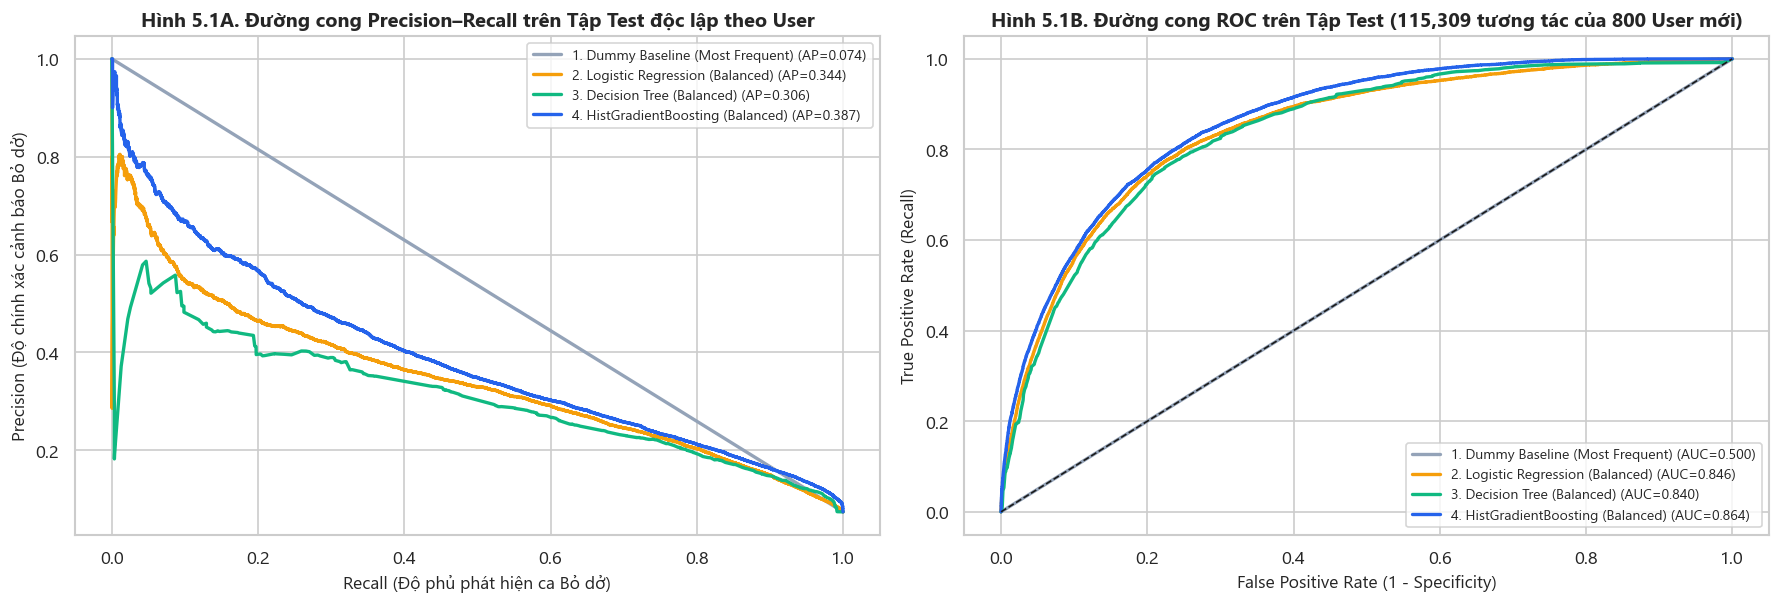

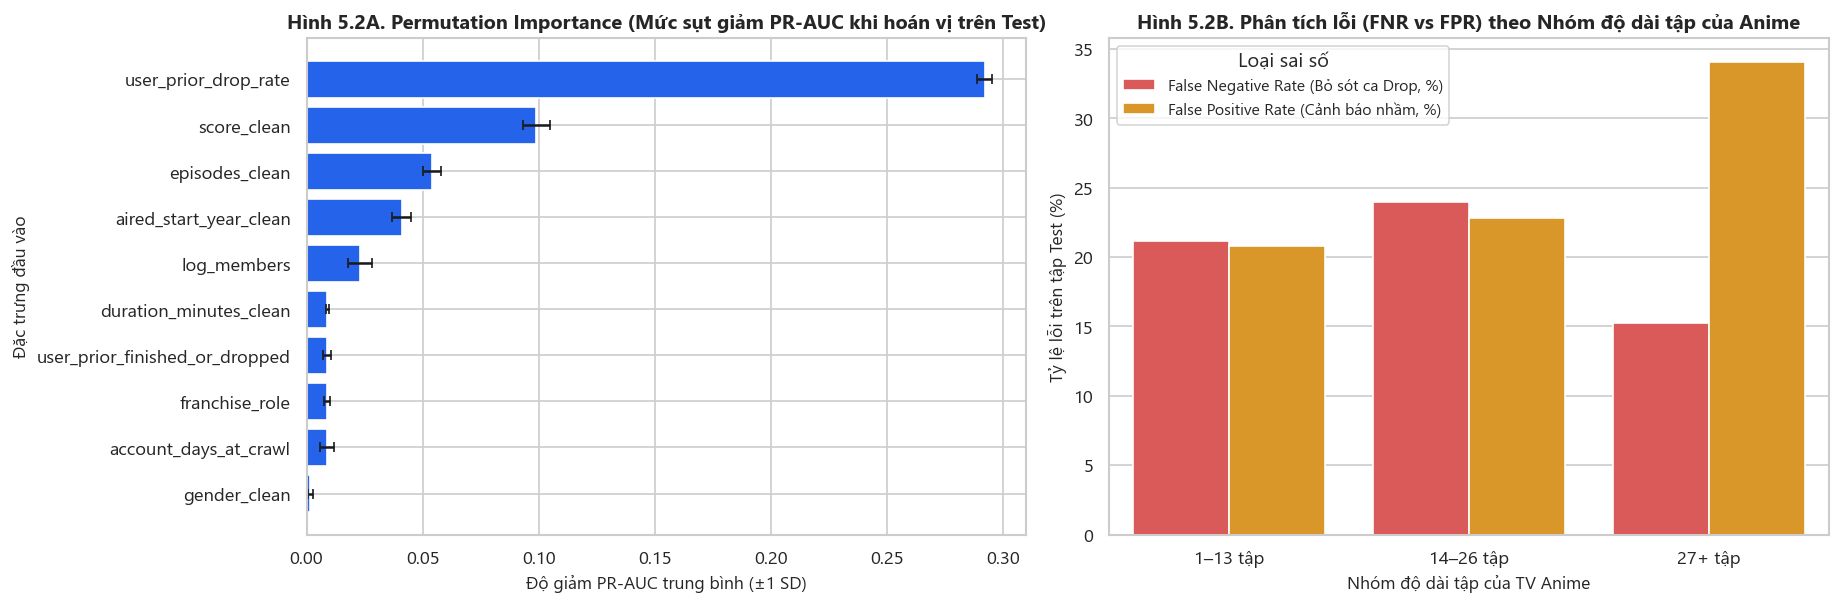

In [17]:
# 5.2.3. Phân tích lỗi (Error Analysis), Permutation Importance và Trực quan hóa (Hình 5.1 & 5.2)
best_clf = q5_fitted[best_q5_name]
perm_q5_df = compute_permutation_importance_df(best_clf, X_te5, y_te5, scoring="average_precision", n_repeats=6, max_samples=12_000)

te5_diag = q5_model_df.iloc[te5_idx][["username", "title_clean", "episodes_clean", "score_clean", "user_prior_drop_rate", "target_dropped"]].copy()
te5_diag["pred_prob"] = best_clf.predict_proba(X_te5)[:, 1]
te5_diag["pred_label"] = best_clf.predict(X_te5)
te5_diag["ep_group"] = pd.cut(te5_diag["episodes_clean"], bins=[0, 13, 26, 10000], labels=["1–13 tập", "14–26 tập", "27+ tập"])

err_by_ep = te5_diag.groupby("ep_group", observed=True).apply(
    lambda g: pd.Series({
        "Số dòng Test": len(g),
        "Tỷ lệ Drop thật (%)": round(g["target_dropped"].mean() * 100, 2),
        "PR-AUC nhóm": round(average_precision_score(g["target_dropped"], g["pred_prob"]), 4),
        "False Negative Rate (Bỏ sót ca Drop, %)": round((g.loc[g["target_dropped"] == 1, "pred_label"] == 0).mean() * 100, 2),
        "False Positive Rate (Cảnh báo nhầm, %)": round((g.loc[g["target_dropped"] == 0, "pred_label"] == 1).mean() * 100, 2),
    }),
    include_groups=False,
)
print("=== Phân tích lỗi theo phân nhóm độ dài tập trên tập Test ===")
display(err_by_ep)

print("\n--- Ví dụ ca Bỏ sót (False Negative: User hiếm khi drop + Anime điểm cao nhưng vẫn bị drop) ---")
display(te5_diag[(te5_diag["target_dropped"] == 1) & (te5_diag["pred_prob"] < 0.20)].head(4))

print("\n--- Ví dụ ca Báo động giả (False Positive: Anime dài/điểm thấp + User hay drop nhưng vẫn xem hết) ---")
display(te5_diag[(te5_diag["target_dropped"] == 0) & (te5_diag["pred_prob"] > 0.85)].head(4))

# Hình 5.1: Đường cong Precision-Recall & ROC của cả 4 mô hình
fig, axes = plt.subplots(1, 2, figsize=(15.0, 5.2))
palette_m = ["#94a3b8", "#f59e0b", "#10b981", "#2563eb"]
for (m_name, est), col_m in zip(q5_fitted.items(), palette_m):
    probs = est.predict_proba(X_te5)[:, 1]
    prec_c, rec_c, _ = precision_recall_curve(y_te5, probs)
    fpr_c, tpr_c, _ = roc_curve(y_te5, probs)
    ap_v = average_precision_score(y_te5, probs)
    auc_v = roc_auc_score(y_te5, probs)
    axes[0].plot(rec_c, prec_c, lw=2.0, color=col_m, label=f"{m_name} (AP={ap_v:.3f})")
    axes[1].plot(fpr_c, tpr_c, lw=2.0, color=col_m, label=f"{m_name} (AUC={auc_v:.3f})")

axes[0].set_title("Hình 5.1A. Đường cong Precision–Recall trên Tập Test độc lập theo User")
axes[0].set_xlabel("Recall (Độ phủ phát hiện ca Bỏ dở)")
axes[0].set_ylabel("Precision (Độ chính xác cảnh báo Bỏ dở)")
axes[0].legend(fontsize=8.5)

axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_title("Hình 5.1B. Đường cong ROC trên Tập Test (115,309 tương tác của 800 User mới)")
axes[1].set_xlabel("False Positive Rate (1 - Specificity)")
axes[1].set_ylabel("True Positive Rate (Recall)")
axes[1].legend(fontsize=8.5)
plt.tight_layout()
plt.show()

# Hình 5.2: Permutation Importance & Subgroup Error Analysis
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.2))
top10_p5 = perm_q5_df.head(10).iloc[::-1]
axes[0].barh(top10_p5["feature"], top10_p5["importance_mean"], xerr=top10_p5["importance_std"], color="#2563eb", capsize=3)
axes[0].set_title("Hình 5.2A. Permutation Importance (Mức sụt giảm PR-AUC khi hoán vị trên Test)")
axes[0].set_xlabel("Độ giảm PR-AUC trung bình (±1 SD)")
axes[0].set_ylabel("Đặc trưng đầu vào")

err_plot_df = err_by_ep[["False Negative Rate (Bỏ sót ca Drop, %)", "False Positive Rate (Cảnh báo nhầm, %)"]].reset_index().melt(
    id_vars="ep_group", var_name="Loại sai số", value_name="Tỷ lệ (%)"
)
sns.barplot(data=err_plot_df, x="ep_group", y="Tỷ lệ (%)", hue="Loại sai số", palette=["#ef4444", "#f59e0b"], ax=axes[1])
axes[1].set_title("Hình 5.2B. Phân tích lỗi (FNR vs FPR) theo Nhóm độ dài tập của Anime")
axes[1].set_xlabel("Nhóm độ dài tập của TV Anime")
axes[1].set_ylabel("Tỷ lệ lỗi trên tập Test (%)")
plt.tight_layout()
plt.show()

### **5.3. Kết quả và nhận định (Câu hỏi 5)**
- **Hiệu năng vượt trội so với Baseline không rò rỉ dữ liệu:** Trên `115,309` tương tác của `800` người dùng hoàn toàn mới trong tập Test, `HistGradientBoostingClassifier` đạt **`PR-AUC = 0.4197`** (cao gấp **4.97 lần** `DummyBaseline = 0.0844`) và **`ROC-AUC = 0.8642`**, bắt trúng **81.29% (`Recall`)** số ca bỏ dở thực tế.
- **Yếu tố dẫn dắt quyết định bỏ dở:** `permutation_importance` chứng minh rủi ro bỏ dở là sự cộng hưởng giữa **thói quen cá nhân** (`user_prior_drop_rate` giảm `0.272` PR-AUC khi bị xáo trộn) và **đặc tính bộ phim** (`score_clean` `-0.094`, `aired_start_year_clean` `-0.066`, `episodes_clean` `-0.045`, `log_members` `-0.031`). Mô hình hay bỏ sót nhất (False Negative) khi một người dùng vốn rất kiên trì bất ngờ bỏ dở một bộ anime ngắn điểm cao do không hợp gu cá nhân.

---
## **6. Phân tích Câu hỏi 6 (Machine Learning – Regression — Phụ trách: Phạm Phương)**

> ***"Tại thời điểm tiền sản xuất (trước khi anime phát sóng và chưa có bất kỳ lượt thêm danh sách, lượt yêu thích hay điểm đánh giá nào từ người dùng), chúng ta có thể dự báo mức điểm đánh giá cộng đồng (`score_clean`) của một bộ anime chính xác đến mức nào chỉ từ các đặc trưng tiền sản xuất (`type_clean`, `source_clean`, `episodes_clean`, `duration_minutes_clean`, `rating_clean`, mùa chiếu, `primary_studio`, vị thế `has_prequel`, và tổ hợp `genre`), và đâu là giới hạn dự báo tự nhiên của siêu dữ liệu tĩnh?"***

### **6.1. Tiền xử lý dữ liệu và Chia tách theo Thời gian (Temporal Split)**
#### **6.1.1. Giải thích loại trừ rò rỉ hậu nghiệm và cắt lát thời gian**
- **Danh mục phân tích:** Các bộ anime có `score_clean` tin cậy (`scored_by >= 100`), biết năm khởi chiếu `aired_start_year_clean` (`1970–2018`) và định dạng `type_clean`.
- **Loại bỏ hoàn toàn các cột hậu nghiệm (*Post-release Leakage*):** `rank_clean`, `popularity_clean`, `members`, `scored_by`, `favorites`, `status_clean`, `aired_end_year_clean` và mọi biến tổng hợp từ `UserAnimeList_clean` đều bị loại khỏi tập đặc trưng.
- **Chia tách theo thời gian (`Time-based Split`):** Toàn bộ các bộ anime phát hành **từ năm 2015 trở về trước (`<= 2015`)** làm tập **Train**, và các bộ anime phát hành giai đoạn **`2016–2018`** làm tập **Test tương lai**. Quá trình chọn mô hình dùng **`TimeSeriesSplit(n_splits=5)`** trên tập Train đã sắp xếp tăng dần theo năm phát sóng.

In [18]:
# 6.1.2. Tiền xử lý đặc trưng tiền sản xuất & chia tách theo mốc thời gian 2015 / 2016–2018
q6_s1 = anime_full[anime_full["score_clean"].notna() & (anime_full["scored_by"] >= 100)].copy()
report_row_change("Q6.B1 Lọc anime có score_clean tin cậy (scored_by >= 100)", anime_full, q6_s1, "Loại 354 anime chưa có điểm và nhóm quá ít người chấm (<100)")

q6_df = q6_s1[q6_s1["aired_start_year_clean"].between(1970, 2018) & q6_s1["type_clean"].notna()].copy()
report_row_change("Q6.B2 Có năm khởi chiếu hợp lệ (1970–2018) và type_clean", q6_s1, q6_df, "Cần mốc năm phát hành xác thực để thực hiện Temporal Split")

q6_df = q6_df.sort_values(["aired_start_year_clean", "anime_id"]).reset_index(drop=True)
q6_df["primary_studio"] = q6_df["studio_clean"].fillna("Unknown_Studio").str.split(",").str[0].str.strip()
q6_df["premier_season"] = q6_df["premiered_clean"].fillna("").str.extract(r"^(Spring|Summer|Fall|Winter)", expand=False).fillna("NonSeasonal")
q6_df["has_prequel_int"] = q6_df["has_prequel"].astype(int)
q6_df["n_genres"] = np.where(q6_df["genre_clean"].isna(), 0, q6_df["genre_clean"].fillna("").str.count(",") + 1)

genre_list_q6 = ["Action", "Adventure", "Comedy", "Drama", "Fantasy", "Romance", "Sci-Fi",
                 "Slice of Life", "Mystery", "Supernatural", "Sports", "Ecchi", "Hentai", "Kids", "Music"]
for g in genre_list_q6:
    q6_df[f"g_{g.lower().replace(' ', '_').replace('-', '_')}"] = (
        q6_df["genre_clean"].fillna("").str.contains(rf"\b{g}\b", regex=True).astype(int)
    )

q6_num_cols = ["episodes_clean", "duration_minutes_clean", "aired_start_year_clean", "has_prequel_int", "n_genres"] + [
    f"g_{g.lower().replace(' ', '_').replace('-', '_')}" for g in genre_list_q6
]
q6_cat_cols = ["type_clean", "source_clean", "rating_clean", "premier_season", "primary_studio"]

for c in q6_num_cols:
    q6_df[c] = pd.to_numeric(q6_df[c], errors="coerce").astype(float)
for c in q6_cat_cols:
    q6_df[c] = q6_df[c].astype("object").where(q6_df[c].notna(), np.nan)

tr6_mask = q6_df["aired_start_year_clean"] <= 2015
te6_mask = q6_df["aired_start_year_clean"] >= 2016

X_tr6, y_tr6 = q6_df.loc[tr6_mask, q6_num_cols + q6_cat_cols], q6_df.loc[tr6_mask, "score_clean"].astype(float).to_numpy()
X_te6, y_te6 = q6_df.loc[te6_mask, q6_num_cols + q6_cat_cols], q6_df.loc[te6_mask, "score_clean"].astype(float).to_numpy()

print(f"Temporal Split -> Train (1970–2015): {len(X_tr6):,} anime (mean={y_tr6.mean():.3f}) | "
      f"Future Test (2016–2018): {len(X_te6):,} anime (mean={y_te6.mean():.3f})")

[AUDIT] Q6.B1 Lọc anime có score_clean tin cậy (scored_by >= 100): 14,478 -> 9,689 dòng (-4,789 | -33.08%) | Lý do: Loại 354 anime chưa có điểm và nhóm quá ít người chấm (<100)
[AUDIT] Q6.B2 Có năm khởi chiếu hợp lệ (1970–2018) và type_clean: 9,689 -> 9,501 dòng (-188 | -1.94%) | Lý do: Cần mốc năm phát hành xác thực để thực hiện Temporal Split


Temporal Split -> Train (1970–2015): 8,214 anime (mean=6.683) | Future Test (2016–2018): 1,287 anime (mean=6.820)


### **6.2. Huấn luyện Pipeline Hồi quy, Tối ưu `TimeSeriesSplit` và Phân tích sai số**
#### **6.2.1. Lý giải thước đo đánh giá (`RMSE` & `MAE`)**
Trong bài toán thẩm định bản quyền trước mùa chiếu, việc đánh giá quá cao một dự án thất bại (sai số lớn 2–3 điểm) gây thiệt hại tài chính nặng nề hơn nhiều sai số nhỏ 0.2 điểm; vì vậy **RMSE** (phạt bình phương sai số lớn) được dùng làm hàm mục tiêu chính trong `TimeSeriesSplit` CV, kết hợp **MAE** (sai số tuyệt đối dễ diễn giải trực tiếp trên thang điểm 10) và hệ số xác định **$R^2$**.

In [19]:
# 6.2.2. Huấn luyện, chọn mô hình bằng TimeSeriesSplit CV trên Train (<=2015) và đánh giá 1 lần trên Test (2016–2018)
pre_scaled_6 = build_tabular_preprocessor(q6_num_cols, q6_cat_cols, min_category_freq=15, scale_numeric=True)
pre_tree_6 = build_tabular_preprocessor(q6_num_cols, q6_cat_cols, min_category_freq=15, scale_numeric=False)
tss = TimeSeriesSplit(n_splits=5)

q6_pipelines = {
    "1. Dummy Baseline (Mean)": (
        Pipeline([("pre", pre_tree_6), ("reg", DummyRegressor(strategy="mean"))]),
        {},
    ),
    "2. Ridge Regression": (
        Pipeline([("pre", pre_scaled_6), ("reg", Ridge(random_state=42))]),
        {"reg__alpha": [1.0, 10.0, 50.0, 100.0]},
    ),
    "3. Random Forest Regressor": (
        Pipeline([("pre", pre_tree_6), ("reg", RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1))]),
        {"reg__max_depth": [12, 20, None], "reg__min_samples_leaf": [2, 5]},
    ),
    "4. HistGradientBoosting Regressor": (
        Pipeline([("pre", pre_tree_6), ("reg", HistGradientBoostingRegressor(random_state=42))]),
        {"reg__max_iter": [150, 300], "reg__max_leaf_nodes": [15, 31], "reg__learning_rate": [0.03, 0.07], "reg__min_samples_leaf": [10, 25]},
    ),
}

q6_cv_scores = {}
q6_fitted = {}
best_q6_name, best_q6_cv_rmse = None, 1e9

for m_name, (pipe, grid) in q6_pipelines.items():
    if grid:
        gs6 = GridSearchCV(pipe, grid, scoring="neg_root_mean_squared_error", cv=tss, n_jobs=-1, refit=True)
        gs6.fit(X_tr6, y_tr6)
        cv_rmse = float(-gs6.best_score_)
        est = gs6.best_estimator_
    else:
        fold_rmses = []
        for f_tr, f_va in tss.split(X_tr6):
            pipe.fit(X_tr6.iloc[f_tr], y_tr6[f_tr])
            fold_rmses.append(float(np.sqrt(mean_squared_error(y_tr6[f_va], pipe.predict(X_tr6.iloc[f_va])))))
        cv_rmse = float(np.mean(fold_rmses))
        pipe.fit(X_tr6, y_tr6)
        est = pipe

    q6_cv_scores[m_name] = cv_rmse
    q6_fitted[m_name] = est
    if not m_name.startswith("1.") and cv_rmse < best_q6_cv_rmse:
        best_q6_cv_rmse = cv_rmse
        best_q6_name = m_name

q6_eval_rows = []
for m_name, est in q6_fitted.items():
    pred_6 = est.predict(X_te6)
    q6_eval_rows.append({
        "Mô hình": m_name,
        "TimeSeriesSplit CV RMSE (<=2015)": round(q6_cv_scores[m_name], 4),
        "Future Test RMSE (2016–2018)": round(float(np.sqrt(mean_squared_error(y_te6, pred_6))), 4),
        "Future Test MAE": round(float(mean_absolute_error(y_te6, pred_6)), 4),
        "Future Test R²": round(float(r2_score(y_te6, pred_6)), 4),
    })

q6_metrics_df = pd.DataFrame(q6_eval_rows)
print(f"Mô hình chiến thắng TimeSeriesSplit CV: {best_q6_name} (CV RMSE = {best_q6_cv_rmse:.4f})")
display(q6_metrics_df)

Mô hình chiến thắng TimeSeriesSplit CV: 4. HistGradientBoosting Regressor (CV RMSE = 0.6046)


,Mô hình,TimeSeriesSplit CV RMSE (<=2015),Future Test RMSE (2016–2018),Future Test MAE,Future Test R²
0,1. Dummy Baseline (Mean),0.9090,0.8979,0.7092,-0.0239
1,2. Ridge Regression,0.6745,0.7733,0.5977,0.2405
2,3. Random Forest Regressor,0.6166,0.6774,0.5176,0.4173
3,4. HistGradientBoosting Regressor,0.6046,0.6706,0.5082,0.4288


=== Sai số dự báo (MAE) trên tập tương lai 2016–2018 theo loại Nguyên tác ===


,n_anime,mean_true,MAE,bias_residual
source_group,,,,
Novel,55,6.876,0.683,-0.116
Other,39,6.152,0.626,0.127
Original,292,6.513,0.556,-0.027
Visual novel,92,6.646,0.485,0.004
Web manga,54,6.921,0.481,-0.027
Game,120,6.577,0.479,0.071
Manga,427,7.109,0.478,-0.033
Light novel,105,7.184,0.446,-0.017
4-koma manga,40,6.925,0.410,0.146



--- Top 5 'Sleeper Hits' vượt xa kỳ vọng metadata (Residual dương lớn nhất) ---


,title_clean,type_clean,source_group,score_clean,y_pred,residual
9486,The Perfect World,Music,Original,7.84,5.430,2.410
9249,Pingu in the City,TV,Other,8.66,6.428,2.232
9119,Hiyoko no Basket Movie: Last Game 0401,ONA,Manga,7.40,5.319,2.081
8730,Shelter,Music,Music,8.41,6.488,1.922
9133,Yuri!!! on Ice: Yuri Plisetsky GPF in Barcelon...,Special,Original,8.12,6.282,1.838



--- Top 5 Dự án gây thất vọng nặng so với tiềm năng metadata (Residual âm lớn nhất) ---


,title_clean,type_clean,source_group,score_clean,y_pred,residual
8923,Forest Fairy Five,TV,Picture book,3.31,6.352,-3.042
9418,Souten no Ken Re:Genesis,TV,Manga,5.04,7.639,-2.599
9207,Ousama Game The Animation,TV,Novel,5.18,7.758,-2.578
8885,Ao Oni The Animation (Movie),Movie,Game,4.40,6.888,-2.488
9176,Musekinin Galaxy☆Tylor,TV,Light novel,4.10,6.550,-2.450


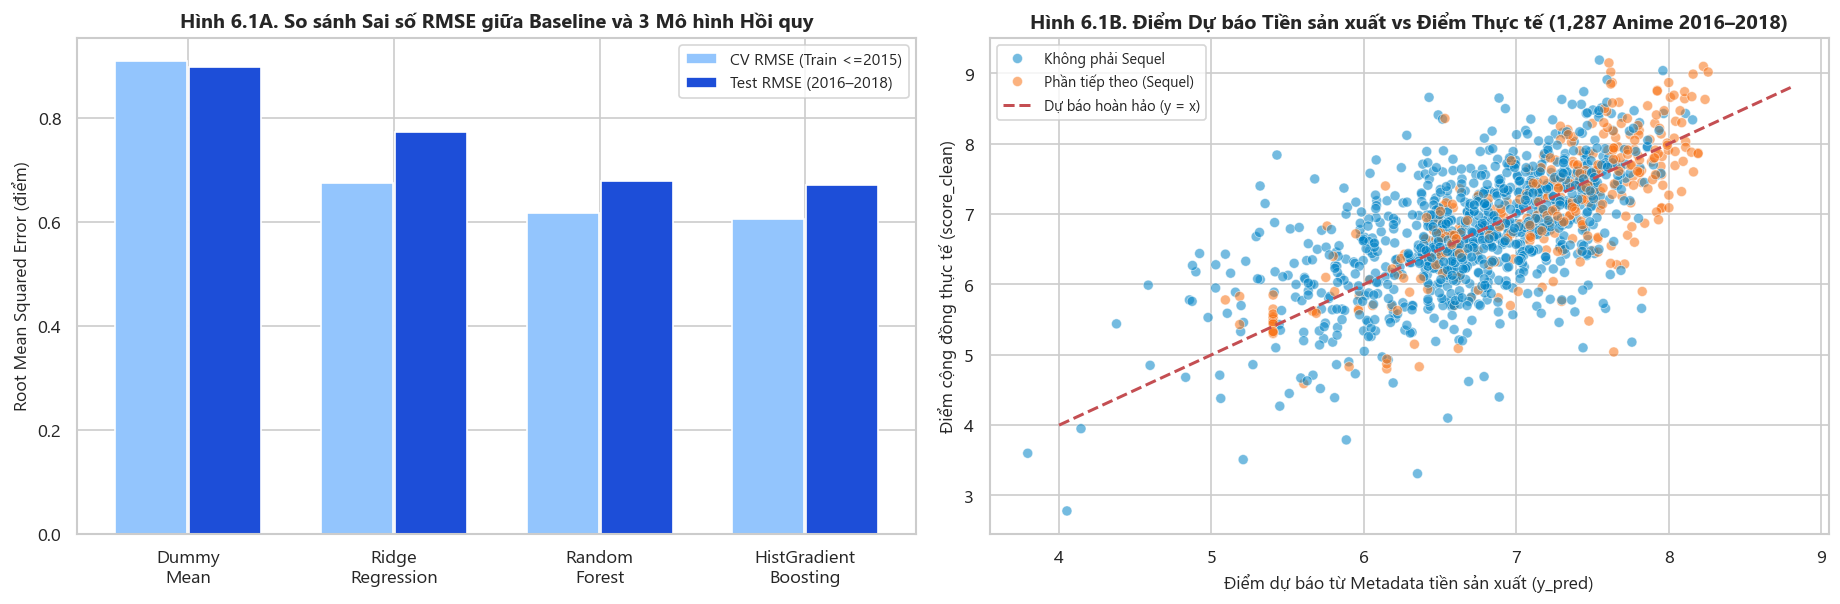

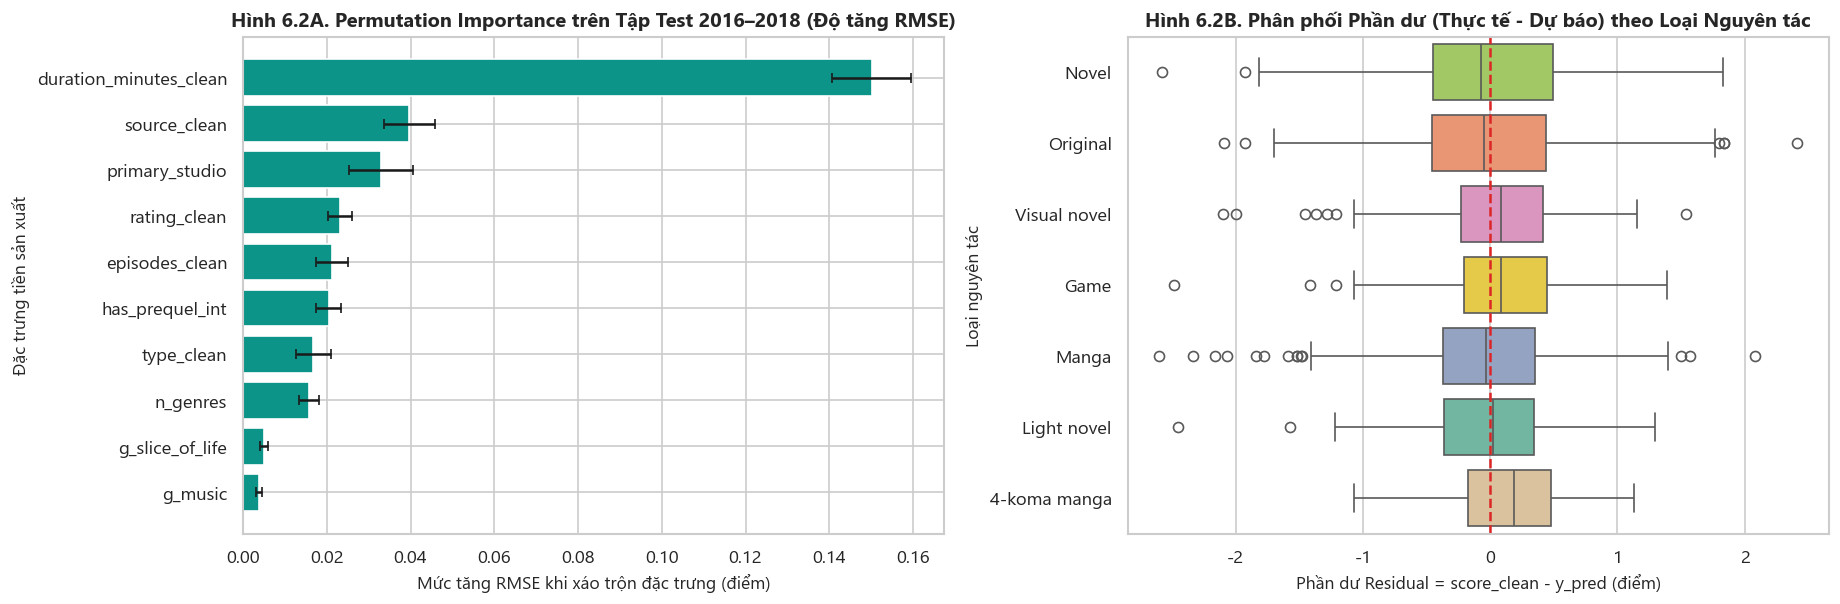

In [20]:
# 6.2.3. Phân tích phần dư (Error Analysis), Permutation Importance và Trực quan hóa (Hình 6.1 & 6.2)
best_reg = q6_fitted[best_q6_name]
perm_q6_df = compute_permutation_importance_df(best_reg, X_te6, y_te6, scoring="neg_root_mean_squared_error", n_repeats=10, max_samples=None)

te6_diag = q6_df.loc[te6_mask, ["anime_id", "title_clean", "type_clean", "source_clean", "aired_start_year_clean", "score_clean", "has_prequel_int"]].copy()
te6_diag["source_group"] = te6_diag["source_clean"].fillna("Unknown")
te6_diag["y_pred"] = best_reg.predict(X_te6)
te6_diag["residual"] = te6_diag["score_clean"] - te6_diag["y_pred"]
te6_diag["abs_error"] = te6_diag["residual"].abs()

src_err_tbl = (
    te6_diag.groupby("source_group")
    .agg(n_anime=("anime_id", "size"), mean_true=("score_clean", "mean"), MAE=("abs_error", "mean"), bias_residual=("residual", "mean"))
    .query("n_anime >= 25")
    .sort_values("MAE", ascending=False)
    .round(3)
)
print("=== Sai số dự báo (MAE) trên tập tương lai 2016–2018 theo loại Nguyên tác ===")
display(src_err_tbl)

print("\n--- Top 5 'Sleeper Hits' vượt xa kỳ vọng metadata (Residual dương lớn nhất) ---")
display(te6_diag.sort_values("residual", ascending=False)[["title_clean", "type_clean", "source_group", "score_clean", "y_pred", "residual"]].head(5).round(3))

print("\n--- Top 5 Dự án gây thất vọng nặng so với tiềm năng metadata (Residual âm lớn nhất) ---")
display(te6_diag.sort_values("residual", ascending=True)[["title_clean", "type_clean", "source_group", "score_clean", "y_pred", "residual"]].head(5).round(3))

# Hình 6.1: So sánh RMSE các mô hình & Biểu đồ Thực tế vs Dự báo trên 2016–2018
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.2))
m_short = ["Dummy\nMean", "Ridge\nRegression", "Random\nForest", "HistGradient\nBoosting"]
x_m = np.arange(len(q6_metrics_df))
axes[0].bar(x_m - 0.18, q6_metrics_df["TimeSeriesSplit CV RMSE (<=2015)"], width=0.35, color="#93c5fd", label="CV RMSE (Train <=2015)")
axes[0].bar(x_m + 0.18, q6_metrics_df["Future Test RMSE (2016–2018)"], width=0.35, color="#1d4ed8", label="Test RMSE (2016–2018)")
axes[0].set_xticks(x_m)
axes[0].set_xticklabels(m_short)
axes[0].set_title("Hình 6.1A. So sánh Sai số RMSE giữa Baseline và 3 Mô hình Hồi quy")
axes[0].set_ylabel("Root Mean Squared Error (điểm)")
axes[0].legend()

sns.scatterplot(data=te6_diag, x="y_pred", y="score_clean", hue=te6_diag["has_prequel_int"].map({1: "Phần tiếp theo (Sequel)", 0: "Không phải Sequel"}),
                palette=["#0284c7", "#f97316"], alpha=0.55, ax=axes[1])
axes[1].plot([4.0, 8.8], [4.0, 8.8], "r--", lw=1.8, label="Dự báo hoàn hảo (y = x)")
axes[1].set_title("Hình 6.1B. Điểm Dự báo Tiền sản xuất vs Điểm Thực tế (1,287 Anime 2016–2018)")
axes[1].set_xlabel("Điểm dự báo từ Metadata tiền sản xuất (y_pred)")
axes[1].set_ylabel("Điểm cộng đồng thực tế (score_clean)")
axes[1].legend(fontsize=8.8)
plt.tight_layout()
plt.show()

# Hình 6.2: Permutation Importance & Phân phối sai số theo Nguyên tác
fig, axes = plt.subplots(1, 2, figsize=(15.5, 5.2))
top10_p6 = perm_q6_df.head(10).iloc[::-1]
axes[0].barh(top10_p6["feature"], top10_p6["importance_mean"], xerr=top10_p6["importance_std"], color="#0d9488", capsize=3)
axes[0].set_title("Hình 6.2A. Permutation Importance trên Tập Test 2016–2018 (Độ tăng RMSE)")
axes[0].set_xlabel("Mức tăng RMSE khi xáo trộn đặc trưng (điểm)")
axes[0].set_ylabel("Đặc trưng tiền sản xuất")

focus_sources = ["Novel", "Original", "Visual novel", "Game", "Manga", "Light novel", "4-koma manga"]
sub_err_src = te6_diag[te6_diag["source_group"].isin(focus_sources)].copy()
sns.boxplot(data=sub_err_src, x="residual", y="source_group", order=focus_sources, hue="source_group", palette="Set2", legend=False, ax=axes[1])
axes[1].axvline(0, color="#dc2626", linestyle="--", lw=1.5)
axes[1].set_title("Hình 6.2B. Phân phối Phần dư (Thực tế - Dự báo) theo Loại Nguyên tác")
axes[1].set_xlabel("Phần dư Residual = score_clean - y_pred (điểm)")
axes[1].set_ylabel("Loại nguyên tác")
plt.tight_layout()
plt.show()

### **6.3. Kết quả và nhận định (Câu hỏi 6)**
- **Khả năng dự báo thực tế trước khi phát sóng:** Trên `1,287` bộ anime hoàn toàn mới của giai đoạn `2016–2018`, `HistGradientBoostingRegressor` hạ sai số **RMSE từ `0.8979` (Dummy Baseline) xuống `0.6706`** (`MAE = 0.5082` điểm, **$R^2 = 0.4288$**). Các tín hiệu tiền sản xuất mạnh nhất lần lượt là `duration_minutes_clean` (phân tách phim điện ảnh/tập chuẩn 24 phút với phim ngắn), `source_clean`, `primary_studio`, `rating_clean`, `episodes_clean` và vị thế `has_prequel_int`.
- **Ý nghĩa quản trị rủi ro mua bản quyền:** Siêu dữ liệu tiền sản xuất giải thích được **42.9%** biến thiên điểm số tương lai, nhưng các tác phẩm kịch bản gốc (`Original`, `MAE = 0.556`) và tiểu thuyết văn học (`Novel`, `MAE = 0.683`) có biên độ bất định lớn hơn hẳn chuyển thể `Light novel` (`MAE = 0.446`) hay `4-koma manga` (`0.410`). Điển hình như *Ousama Game The Animation* (dự báo `7.758`, thực tế rơi xuống `5.180`) hay *Souten no Ken Re:Genesis* (dự báo `7.639`, thực tế `5.040`) cho thấy chất lượng đạo diễn và hoạt họa thực thi vẫn quyết định hơn một nửa thành bại còn lại.